## Process 10x satseq data

Demonstates how we ran cellranger, and also used barcode-variant map from pacbio to label variants in 10x data

Produces filtered 10x data set (.h5ad file) with variants labelled

This particular notebook for 4T1 tumor data in Laughney-MD-16637_2024_06_11/4T1

Other satseq 10x datasets were processed in the same way. Except in this case, we chose to remove one of the samples (4T1_4) due to quality issues. For other data sets, we kept all samples.


The repository comes with demo data, the notebook can be run on this data (set use_demo_data=True in cell 9). In that case it will take a few minutes to run. With actual data, it could be a couple hours, depending on number of samples/cells.


## Preprocessing

To run on raw fastq files from 10x, there are two steps that must be run before this notebook:

1. Run cellranger on fastq files. The fastq files have been submitted to GEO and will be linked to BioProject PRJNA1552726.  We used cellranger v 8.0.1. The script we can be found in the repository subdirectory: `bash/run_cellranger.sh`
2. After running cellranger, get consensus barcode for each cell. This was done using the script `bash/bowtie_pileup.sh`. It groups feature reads by cell (which are assigned by cellranger in previous step), and then aligns all the feature reads from the same cell together, to get a consensus barcode per cell. The resulting file will be placed in `outs/barcode_consensus_simple_bothref.fa.gz` in the cellranger_out directory. This script used samtools v1.20 and bowtie2 version 2.5.1.

Alternatively, the necessary output files from the previous two steps are also included in the GEO submission. For each sample there should be the following files: `raw_feature_bc_matrix.h5`, `molecule_info.h5`, and `barcode_consensus_simple_bothref.fa.gz`. These would need to be downloaded and placed in a directory with the structure:



```text
cellranger_out_dir/
├── sample1/
│   ├── outs/
│   │   └── raw_feature_bc_matrix.h5
│   │   └── molecule_info.h5
│   │   └── barcode_consensus_simple_bothref.fa.gz
├── sample2/
│   ├── outs/
│   │   └── raw_feature_bc_matrix.h5
│   │   └── molecule_info.h5
│   │   └── barcode_consensus_simple_bothref.fa.gz
├── sample2/
| ...
```


The pipeline also requires a barcode mapping file (`bcmapfile`), which is generated by the pacbio processing notebooks in this directory. The final barcode maps used can be found in the main repository here:
```code
SatSeq_Bulk_DNAseq_Analysis/assets/bcmap_EO771_2025_02_27.txt.gz  # for EO771.lmb
SatSeq_Bulk_DNAseq_Analysis/assets/bcmap_4T1_2025_02_27.txt.gz    # for 4T1
```

In [1]:
import gzip
import multiprocessing
import os
import sys
import time
from importlib.metadata import version

import editdistance
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from kneed import KneeLocator
from scipy.sparse import coo_matrix, csr_matrix

In [2]:
print(f"Python: {sys.version.split()[0]}")

packages = [
    "editdistance",
    "h5py",
    "matplotlib",
    "numpy",
    "pandas",
    "scanpy",
    "kneed",
    "scipy"
]

for package in packages:
    print(f"{package}: {version(package)}")

Python: 3.10.12
editdistance: 0.8.1
h5py: 3.10.0
matplotlib: 3.8.3
numpy: 1.26.4
pandas: 2.2.1
scanpy: 1.9.8
kneed: 0.8.5
scipy: 1.12.0


In [3]:
sys.path.append('python')

import scrna_processing as scrpr

In [4]:
# This pipeline requires mmseqs for aligning pacbio and 10x barcodes

# If you have it installed already, set path to it here:
mmseqs_executable='/opt/mmseqs/bin/mmseqs'

# Or, you can install the latest version with (uncomment and run)
# ! mkdir -p /opt
# cd /opt && wget https://dev.mmseqs.com/latest/mmseqs-linux-avx2.tar.gz && tar -zxf mmseqs-linux-av2.tar.gz
# mmseqs_executable='/opt/mmseqs/bin/mmseqs'

# The mmseqs version used here is 8ef870f95af2a3ee474c2cdbb845f5f007fe5be6, which was the lastet version as of Feb 10, 2025.
# This version can be installed with:
# !mkdir -p /opt
# ! cd /opt && git clone https://github.com/soedinglab/MMseqs2.git && cd MMseqs2 && git checkout 8ef870f95af2a3ee474c2cdbb845f5f007fe5be6 && mkdir build
# ! cd /opt/MMseqs2/build && cmake -DCMAKE_BUILD_TYPE=RELEASE -DCMAKE_INSTALL_PREFIX=. .. && make -j && make install
# mmseqs_executable='/opt/MMseqs2/build/bin/mmseqs'


In [5]:
print(mmseqs_executable)
!{mmseqs_executable} version

/opt/mmseqs/bin/mmseqs
8ef870f95af2a3ee474c2cdbb845f5f007fe5be6


In [6]:
# set this to SatSeq_10x_Variant_Calling dir from github repository

basedir='/data/satseq_processing/SatSeq_10x_Variant_Calling'
os.chdir(basedir)

In [7]:
output_dir='output/02_10x_processing'
print(output_dir)
!mkdir -p {output_dir}

output/02_10x_processing


In [8]:
!mkdir -p {output_dir}

## Set input directories

In [9]:
# Set this to True to run on demo data that comes with github repository. It will run fast but some of the plots will be very sparse
use_demo_data = False

In [10]:
# This is to run on example data, which contains 500 randomly selected cells each from two EO771.lmb tumor samples, as well as 250 filtered cells

if use_demo_data:
    
    cellranger_out_dir='data/examples/satseq_10x_demo_with_filtering/cellranger_output'
    samples = ['EO771_1_subset500', 'EO771_2_subset500']
    
    bcmapfile = f'../SatSeq_Bulk_DNAseq_Analysis/assets/bcmap_EO771_2025_02_27.txt.gz'
    
    
    # give a name to identify output files from this notebook run
    run_name='EO771_subsets'
    
    
    # Because this is sample data, it doesn't work for demonstrating cell size filtering. So we are also providing the UMI distribution for all cells in the sample.
    # When running on real data, set this to None, it will be inferred from the data
    full_umi_sizes = {}
    for sample in samples:
        with np.load(f'{cellranger_out_dir}/{sample}_full_barcode_gex_umi_totals.npz'.replace('_subset500', ''), allow_pickle=False) as f:
              full_umi_sizes[sample] = f['gex_umis']
    

else:
    # to run on real data, you will need to download data from GEO and organize as described in the header of this notebook

    condition='tumor'  # can be 'tumor', 'cGAMP', 'H2O'
    celltype='EO771'   # can be 'EO771', '4T1'
    bcmapfile = f'../SatSeq_Bulk_DNAseq_Analysis/assets/bcmap_EO771_2025_02_27.txt.gz'
    run_name = f'{celltype}_{condition}'
    full_umi_sizes = None   # for real data, use observed sizes.
    
    cellranger_out_dir=''
    if condition == 'tumor':
        cellranger_out_dir=f'/workdir/satseq/Laughney-MD-16637_2024_06_11/{celltype}'
        samples = [f'{celltype}_{i+1}' for i in range(8)]
    elif condition=='cGAMP' or condition=='H2O':
        cellranger_out_dir=f'/workdir/satseq/Laughney-AO-17382-2024_10_22/{celltype}'
        samples = [f'{celltype}_{condition}_{i+1}' for i in range(4)]
    if cellranger_out_dir=='':
        print('error: Invalid celltype/condition')
    print(f'cellranger_out_dir={cellranger_out_dir}')
    print('samples: ' + ' '.join(samples))
    

cellranger_out_dir=/workdir/satseq/Laughney-MD-16637_2024_06_11/EO771
samples: EO771_1 EO771_2 EO771_3 EO771_4 EO771_5 EO771_6 EO771_7 EO771_8


In [11]:
# The code repository comes with two feature_ref files, used in the cellranger pipeline:
# `data/twist_mSTING_full_feature_ref_v2.csv' and `data/twist_mSTING_full_feature_ref_v3.csv`

# All the analysis from the paper was done with v2. If you are using data from the paper (including demo data), set this to v2.

# However if you do your own alignments, we recommend using the v3 version, which has minor errors fixed (some variants mis-named)

# If the following variable is set to 'v2', the correction to variant names will be done in this notebook.

# tl;dr leave this set to v2 unless you have re-run cellranger with newest feature_ref file.
feature_ref_version='v2'

## Read in data

In [12]:
adatas = [sc.read_10x_h5(cellranger_out_dir + '/' + s + '/outs/raw_feature_bc_matrix.h5', gex_only=False) for s in samples]

/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_name

In [13]:
for i,s in enumerate(samples):
    adatas[i].obs['sample'] = s
    adatas[i].obs['sample'] = adatas[i].obs['sample'].astype(str)
    adatas[i].obs.index = [f'{x}-{i}' for x in adatas[i].obs.index]

### Get read depth matrix from cellRanger output

In [14]:
for i,s in enumerate(samples):
    readData = h5py.File(cellranger_out_dir + '/' + s + '/outs/molecule_info.h5', 'r')
    read_matrix = csr_matrix((readData['count'], (readData['barcode_idx'], readData['feature_idx'])), shape=adatas[i].shape)

    #gene_ids should be unique
    gene_ids = adatas[i].var.gene_ids
    geneTable = gene_ids.value_counts()
    print(f"Num unique gene IDs: {sum(geneTable==1)}\nNum non-unique gene IDs: {sum(geneTable > 1)}")
    if sum(geneTable > 1) > 0:
        print("ERROR: Gene IDs not unique")
    gene_names = adatas[i].var.index
    geneTable = gene_names.value_counts()
    print(f"Num unique gene names: {sum(geneTable==1)}\nNum non-unique gene names: {sum(geneTable > 1)}")
    if sum(geneTable > 1) > 0:
        tdata = adatas[i].copy().T
        dupGenes = geneTable[geneTable > 1].index
        #print(f"Duplicated gene [indices]")
        removeGenes = np.zeros(len(gene_names), bool)
        for dupGene in dupGenes:
            idx = [i for i in range(len(gene_names)) if gene_names[i] == dupGene] 
            #print(dupGene,idx)
            for j in range(len(idx)):
                if (j != 0):
                    tdata.X[idx[0],:] += tdata.X[idx[j],:]
                    read_matrix[:,idx[0]] += read_matrix[:,idx[j]]
                    removeGenes[idx[j]] = True
        tdata = tdata[~removeGenes]
        adatas[i] = tdata.copy().T
        read_matrix = read_matrix[:,~removeGenes]
        print(f"Combined {len(dupGenes)} genes; removed {sum(removeGenes)} columns")
    adatas[i].layers['read_matrix'] = read_matrix

Num unique gene IDs: 32677
Num non-unique gene IDs: 0
Num unique gene names: 32599
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns
Num unique gene IDs: 32677
Num non-unique gene IDs: 0
Num unique gene names: 32599
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns
Num unique gene IDs: 32677
Num non-unique gene IDs: 0
Num unique gene names: 32599
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


... (7 outputs left out)

/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns
Num unique gene IDs: 32677
Num non-unique gene IDs: 0
Num unique gene names: 32599
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns


## Separate variant and genes in adatas

STING variants are stored in adata columns with `adata.var['feature_type'] == 'Custom'`, we don't want to treat these as genes, instead store these counts in `adata.obsm['variant_counts']` and `adata.obsm['variant_reads']`

In [15]:
genes = list(adatas[0].var.loc[adatas[0].var['feature_types'] == 'Gene Expression'].index)
variants = list(adatas[0].var.loc[adatas[0].var['feature_types'] == 'Custom'].index)

for i in range(len(adatas)):
    if sum(np.array(adatas[i].var.loc[adatas[0].var['feature_types'] == 'Gene Expression'].index) != np.array(genes)) != 0:
        print('error1')
    if sum(np.array(adatas[i].var.loc[adatas[0].var['feature_types'] == 'Custom'].index) != np.array(variants)) != 0:
        print('error2')
print(len(genes), len(variants))

32245 392


In [16]:
for i in range(len(adatas)):
    print(i, adatas[i].shape)
    adatas[i].obsm['variant_counts'] = adatas[i][:,variants].X
    adatas[i].obsm['variant_reads'] = adatas[i][:,variants].layers['read_matrix']
    adatas[i] = adatas[i][:,genes]
    print(i, adatas[i].shape)

0 (1543775, 32637)
0 (1543775, 32245)
1 (1658876, 32637)
1 (1658876, 32245)
2 (1355876, 32637)
2 (1355876, 32245)
3 (1356281, 32637)
3 (1356281, 32245)
4 (1656909, 32637)
4 (1656909, 32245)
5 (1523170, 32637)
5 (1523170, 32245)
6 (1567188, 32637)
6 (1567188, 32245)
7 (1380144, 32637)
7 (1380144, 32245)


In [17]:
for i in range(len(adatas)):
    for f in ['variant_counts', 'variant_reads']:
        adatas[i].obsm[f] = np.array(adatas[i].obsm[f].todense())

/tmp/ipykernel_10249/1318859062.py:3: ImplicitModificationWarning: Setting element `.obsm['variant_counts']` of view, initializing view as actual.
  adatas[i].obsm[f] = np.array(adatas[i].obsm[f].todense())


### Filter cells based on size

In [18]:
# calculate mtFrac and library_size first
for i,adata in enumerate(adatas):
    msum = np.array(adata.X.sum(axis=1)).flatten()
    mt_genes = [x for x in adata.var.index if x.startswith('mt')]
    mt = np.array(adata[:,mt_genes].X.sum(axis=1)).flatten()
    f = msum == 0
    adatas[i].obs['library_size'] = msum
    adatas[i].obs['mt_frac'] = 0.0
    adatas[i].obs.loc[adatas[i].obs['library_size'] > 0,'mt_frac'] = mt[~f]/msum[~f]

__First look at overview of sizes__

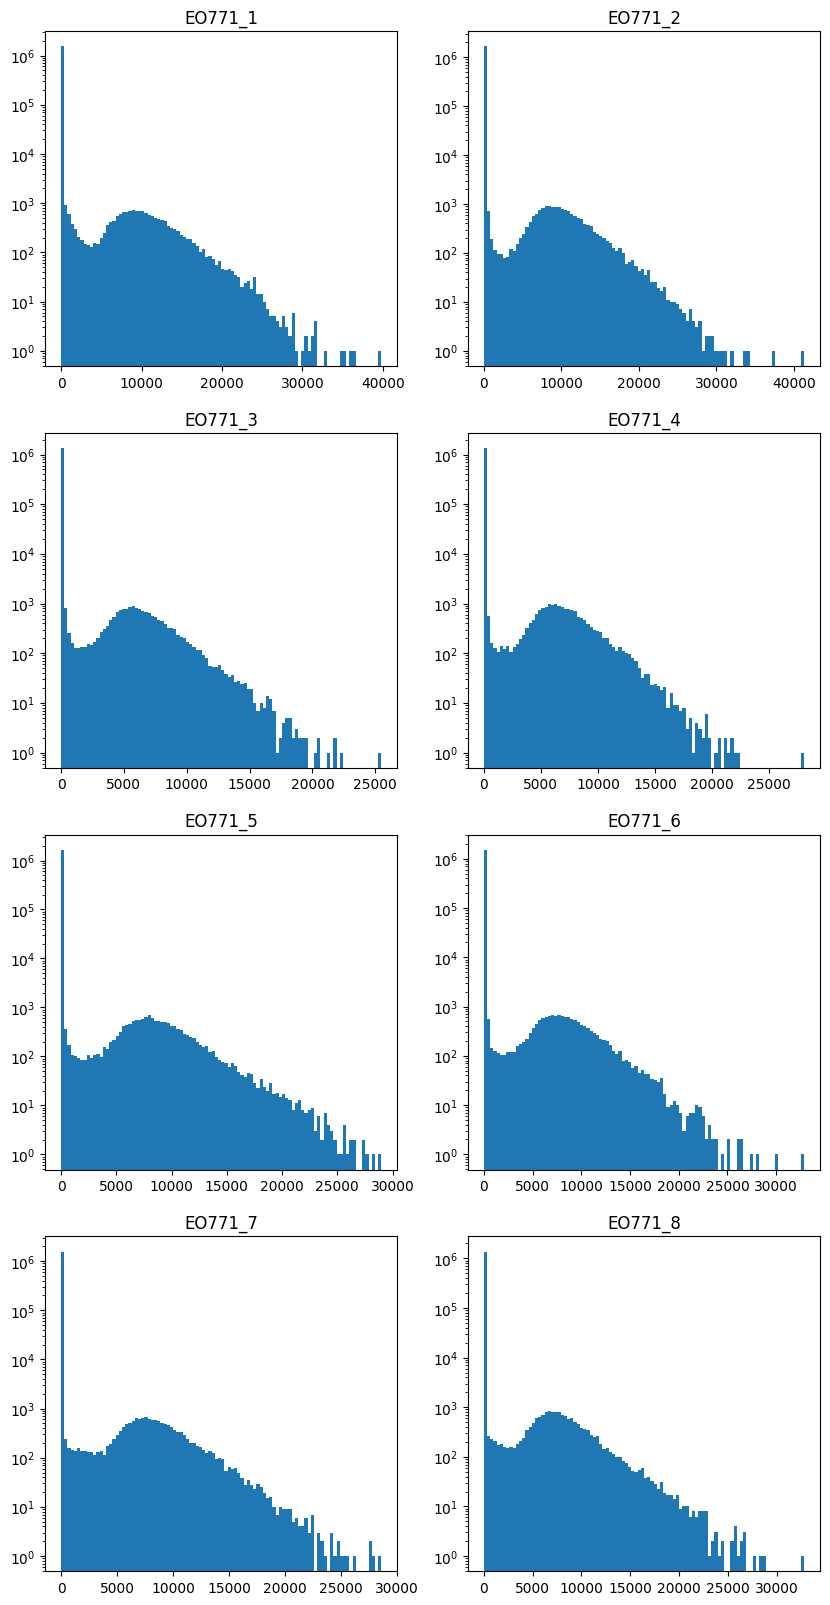

In [19]:
nrows=int(np.ceil(len(samples)/2))
ncols=2
plt.subplots(nrows=nrows,ncols=ncols,figsize=(ncols*5,nrows*5))
for i in range(len(adatas)):
    plt.subplot(nrows,ncols,i+1)
    vals = np.array(np.sum(adatas[i].X, axis=1)).flatten()
#    vals = vals[vals > 100]
    plt.hist(vals, bins=100)
    plt.yscale('log')
    #plt.axvline(np.log10(2000))
    plt.title(adatas[i].obs['sample'].iloc[0])
    
plt.show()

__Now zoom in on range from first to second peak. May need to adjust maxx and binsize below, want smallest binsize that results in relatively smooth plot and good choice of cutoff for all samples. Maybe stick with 200 if it looks good__

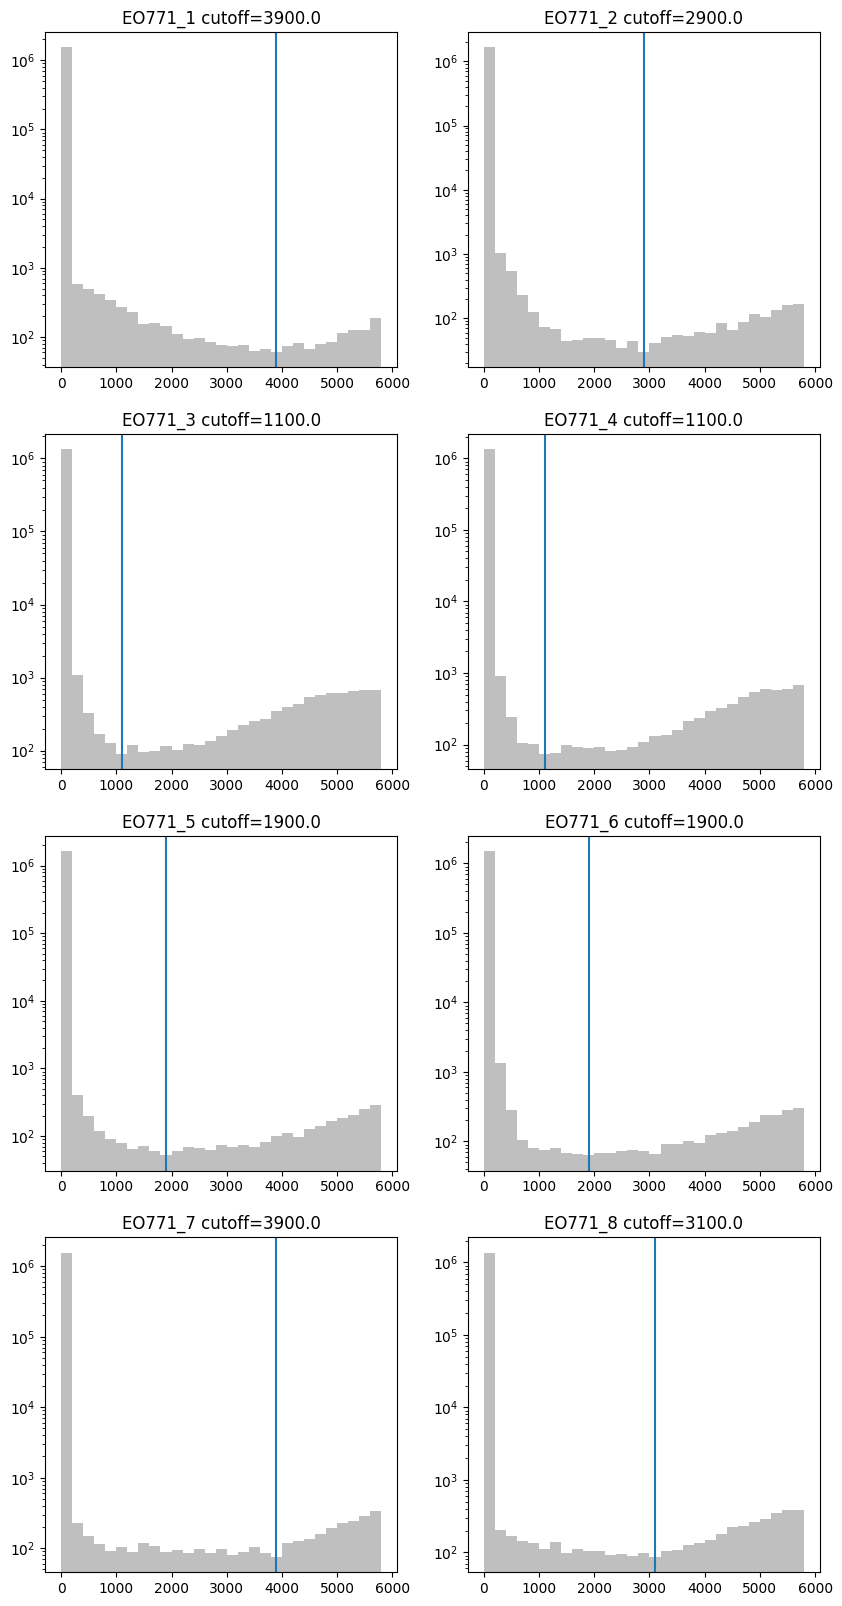

In [20]:
binsize=200
maxx = 6000   # This is upper limit of plot, we want to zoom in on region between size peaks
bins = np.arange(0, maxx, binsize)

# set true to overlay plot with low mtFrac
plotMito=False

cutoffs = []
plt.subplots(nrows=nrows,ncols=ncols,figsize=(ncols*5,nrows*5))
for i in range(len(adatas)):
    plt.subplot(nrows,ncols,i+1)
    if full_umi_sizes is not None and full_umi_sizes[sample] is not None:
        # This is for demo data
        vals = full_umi_sizes[sample]
    else:
        vals = np.array(np.sum(adatas[i].X, axis=1)).flatten()
#    vals = vals[vals > 100]
    h = plt.hist(vals, bins=bins, color='gray', alpha=0.5)
    f = adatas[i].obs['mt_frac'] < 0.05
    if plotMito:
        plt.hist(vals[f], bins=bins, color='red', alpha=0.5)
    plt.yscale('log')
    hvals = pd.DataFrame({'xmid':(h[1][1:] + h[1][:-1])/2.0, 'count':h[0]})#.sort_values(by='count')
    minidx = np.argmin(hvals['count'])
    f = hvals['count'] >= 0  # choose all to start
    while (minidx == sum(f)-1):
        f = (f) & (hvals.index != minidx)
        minidx = np.argmin(hvals.loc[f,'count'])
    cutoff = hvals.loc[minidx,'xmid']
    cutoffs.append(cutoff)
    plt.axvline(cutoff)
    sample = adatas[i].obs['sample'].iloc[0]
    plt.title(f'{sample} cutoff={cutoff}')
plt.show()

__This just shows how cutoffs look on the CDF plot__

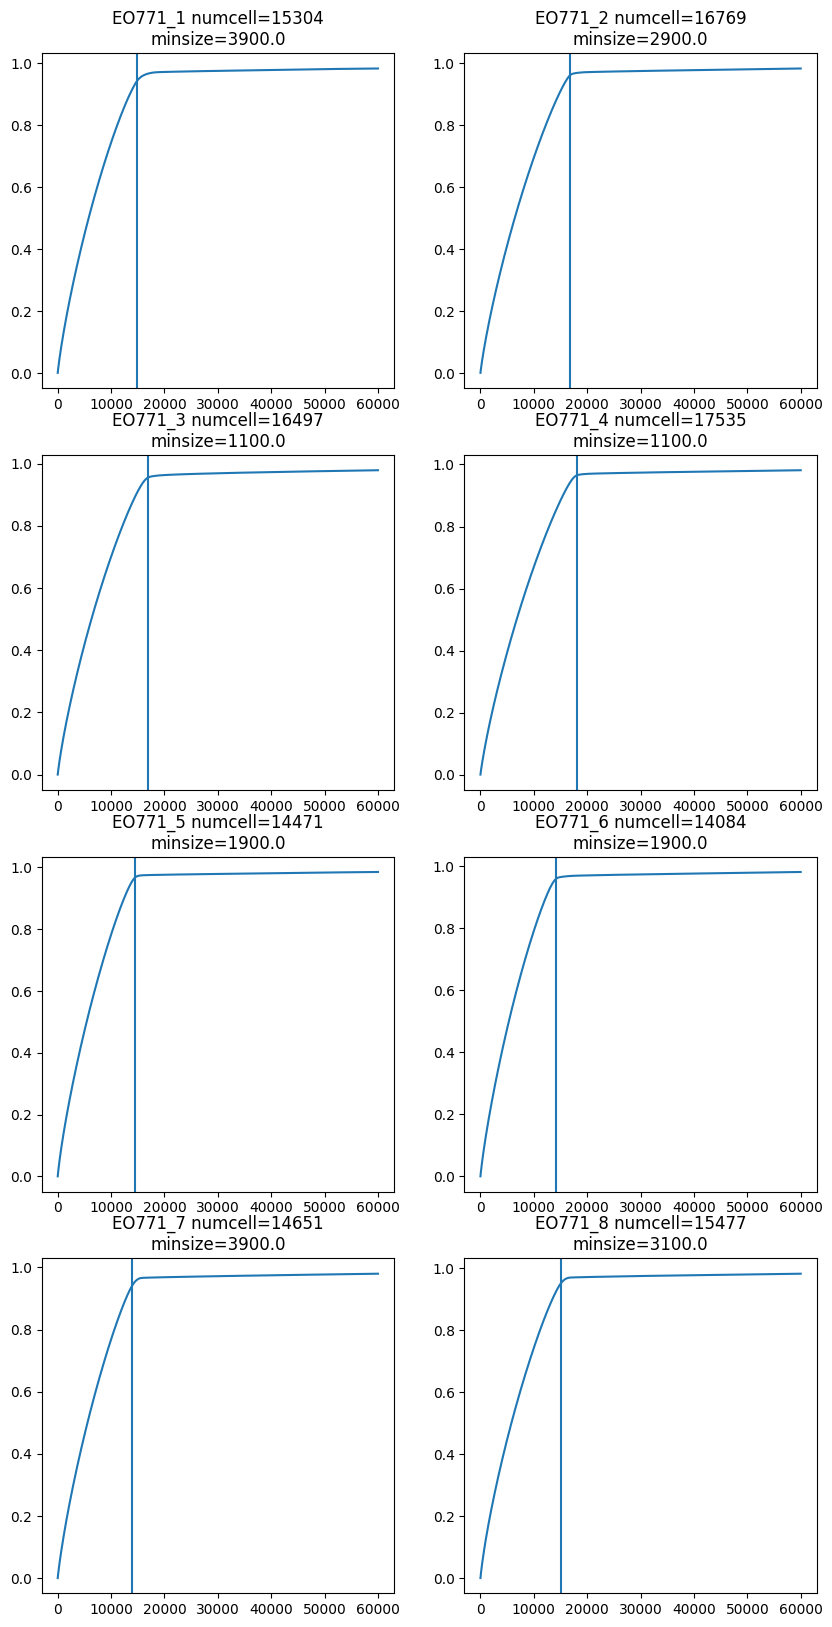

In [21]:
plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
idx=1

for i,s in enumerate(samples):
    plt.subplot(nrows, ncols, idx)
    idx=idx+1
    molecules = coo_matrix(adatas[i].X)
    if full_umi_sizes is not None and full_umi_sizes[sample] is not None:
        sizes = -full_umi_sizes[samples[i]].astype(np.float64)
    else:
        sizes = np.array(np.sum(molecules, axis=1)).flatten()*-1.0
    sizes.sort()
    csizes = sizes.cumsum()*-1.0
    csizes = csizes/np.max(csizes)
    maxcells=min(60000, len(sizes))
    kneedle = KneeLocator(np.arange(0, maxcells), csizes[:maxcells])
    #kneedle.plot_knee(plt.gca())
    plt.plot(np.arange(0, maxcells), csizes[:maxcells])
    plt.axvline(sum(-sizes >= cutoffs[i]))
    #print(kneedle.knee)
    minsize = -sizes[kneedle.knee]
    #print(minsize)
    #plt.xlim((0, maxcells))
    plt.title(f'{s} numcell={kneedle.knee}\nminsize={cutoffs[i]}')

0 EO771_1
1 EO771_2
2 EO771_3
3 EO771_4
4 EO771_5
5 EO771_6
6 EO771_7
7 EO771_8


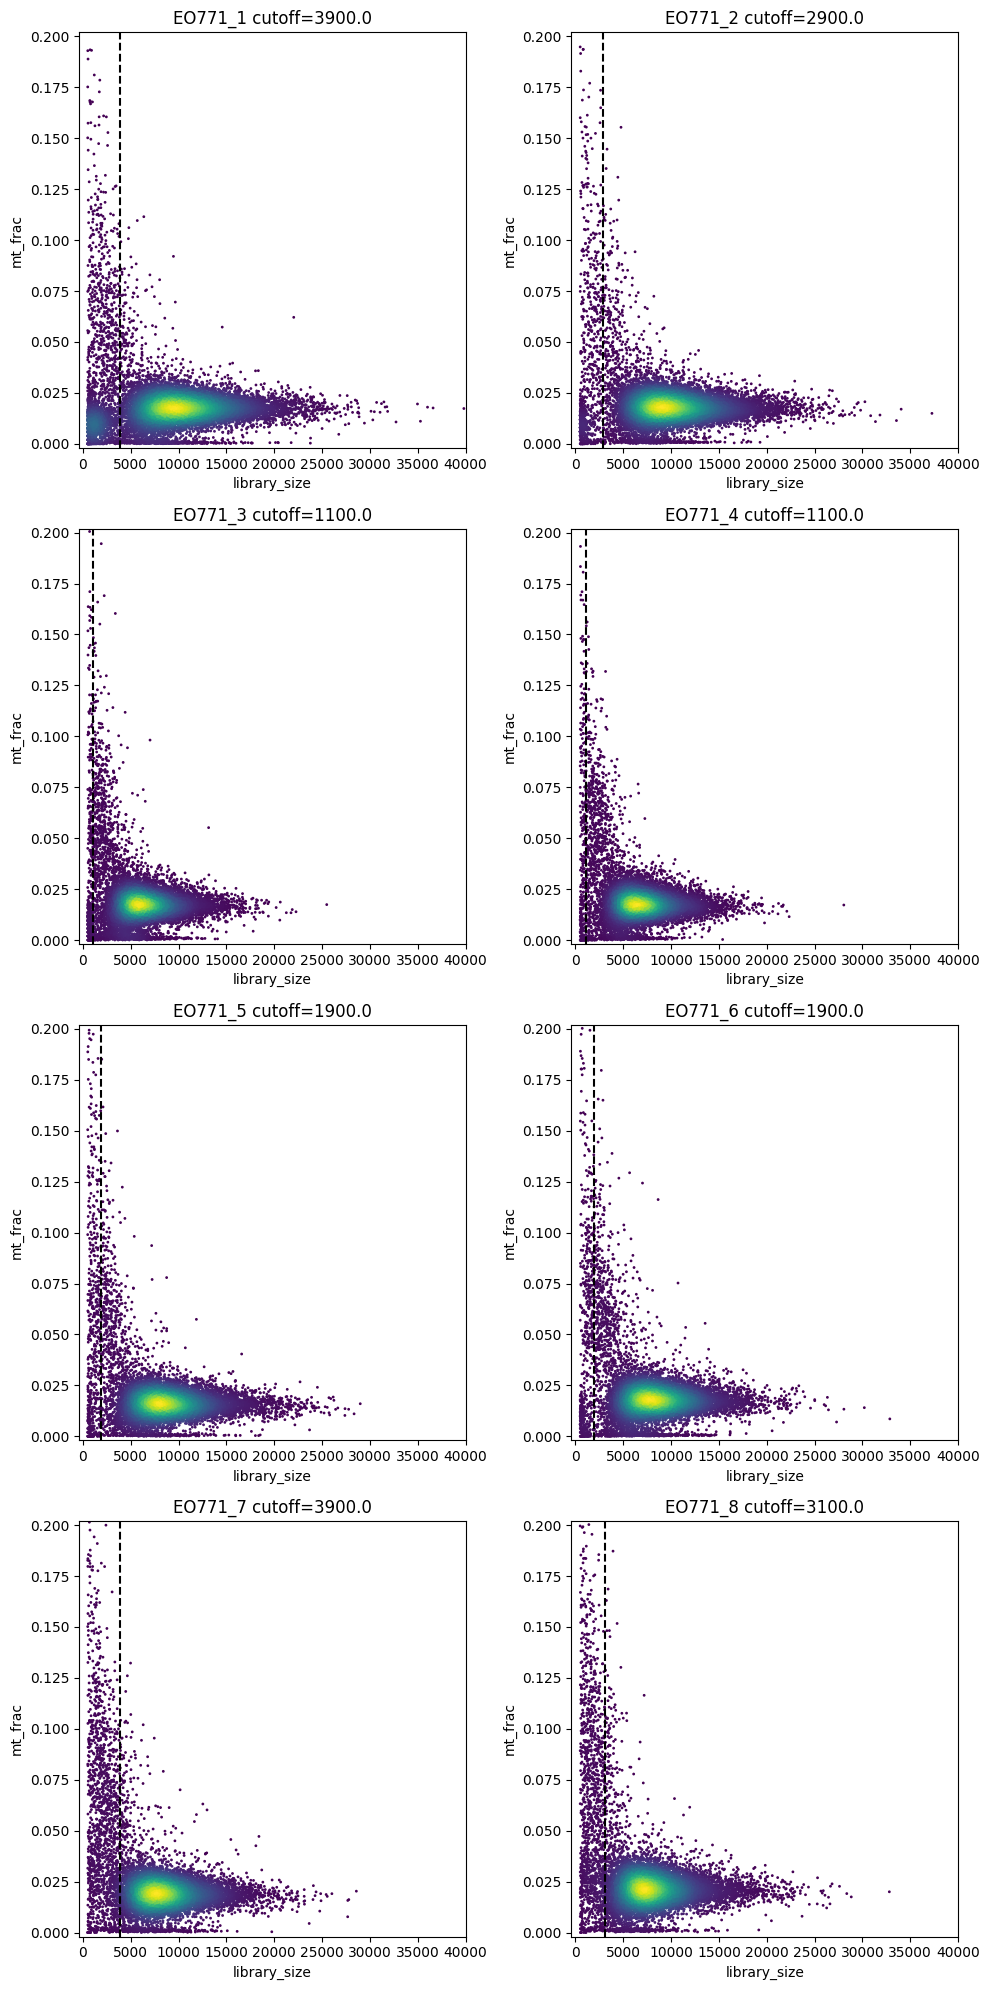

In [22]:
plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
idx=1
maxval = np.max(np.array([np.max(adata.obs['library_size']) for adata in adatas]))
maxmt = np.max(np.array([np.max(adata.obs['mt_frac']) for adata in adatas]))
maxmt=0.2
for i,adata in enumerate(adatas):
    f = adata.obs['library_size'] > 500 # skip very empty cells, otherwise plot_scatter_continuous blows up
    x = np.array(adata.obs.loc[f,'library_size'])
    y = np.array(adata.obs.loc[f,'mt_frac'])
    sample = adata.obs['sample'].iloc[0]
    print(i, sample)
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    scrpr.plot_scatter_continuous(x, y, ax=ax, colorbar=False, s=1)
    ax.set_xlabel('library_size')
    ax.set_ylabel('mt_frac')
    ax.set_title(f'{sample} cutoff={cutoffs[i]}')
    #ax.set_xlim((-maxval*0.01, maxval*1.01))
    ax.set_xlim((-maxval*0.01, 40000.0))
    ax.set_ylim((-maxmt*0.01, maxmt*1.010))
    plt.axvline(cutoffs[i], color='black', linestyle='--')
plt.tight_layout()
plt.show()

In [23]:
for i in range(len(adatas)):
    adatas[i] = adatas[i][adatas[i].obs['library_size'] >= cutoffs[i]]

In [24]:
adata = sc.concat(adatas, merge='same')
adata.uns['variants'] = variants

__REMOVE 4T1_4 due to quality issues__

In [25]:
if '4T1_4' in samples:
    print('Removing 4T1_4 from dataset')
    adata = adata[adata.obs['sample'] != '4T1_4']
    
    samples = [x for x in samples if x!='4T1_4']
    len(samples)

In [26]:
adata.shape

(124124, 32245)

In [27]:
adata.obs['sample'].value_counts()

sample
EO771_4    17993
EO771_3    16886
EO771_2    16776
EO771_8    15038
EO771_1    14907
EO771_5    14548
EO771_6    14138
EO771_7    13838
Name: count, dtype: int64

## Some cell filtering/quality

### Mitochondrial filter

Cells removed: 0
Cells remaining: 14907
Cells removed: 0
Cells remaining: 16776
Cells removed: 1
Cells remaining: 16885
Cells removed: 1
Cells remaining: 17992
Cells removed: 0
Cells remaining: 14548
Cells removed: 1
Cells remaining: 14137
Cells removed: 0
Cells remaining: 13838
Cells removed: 0
Cells remaining: 15038


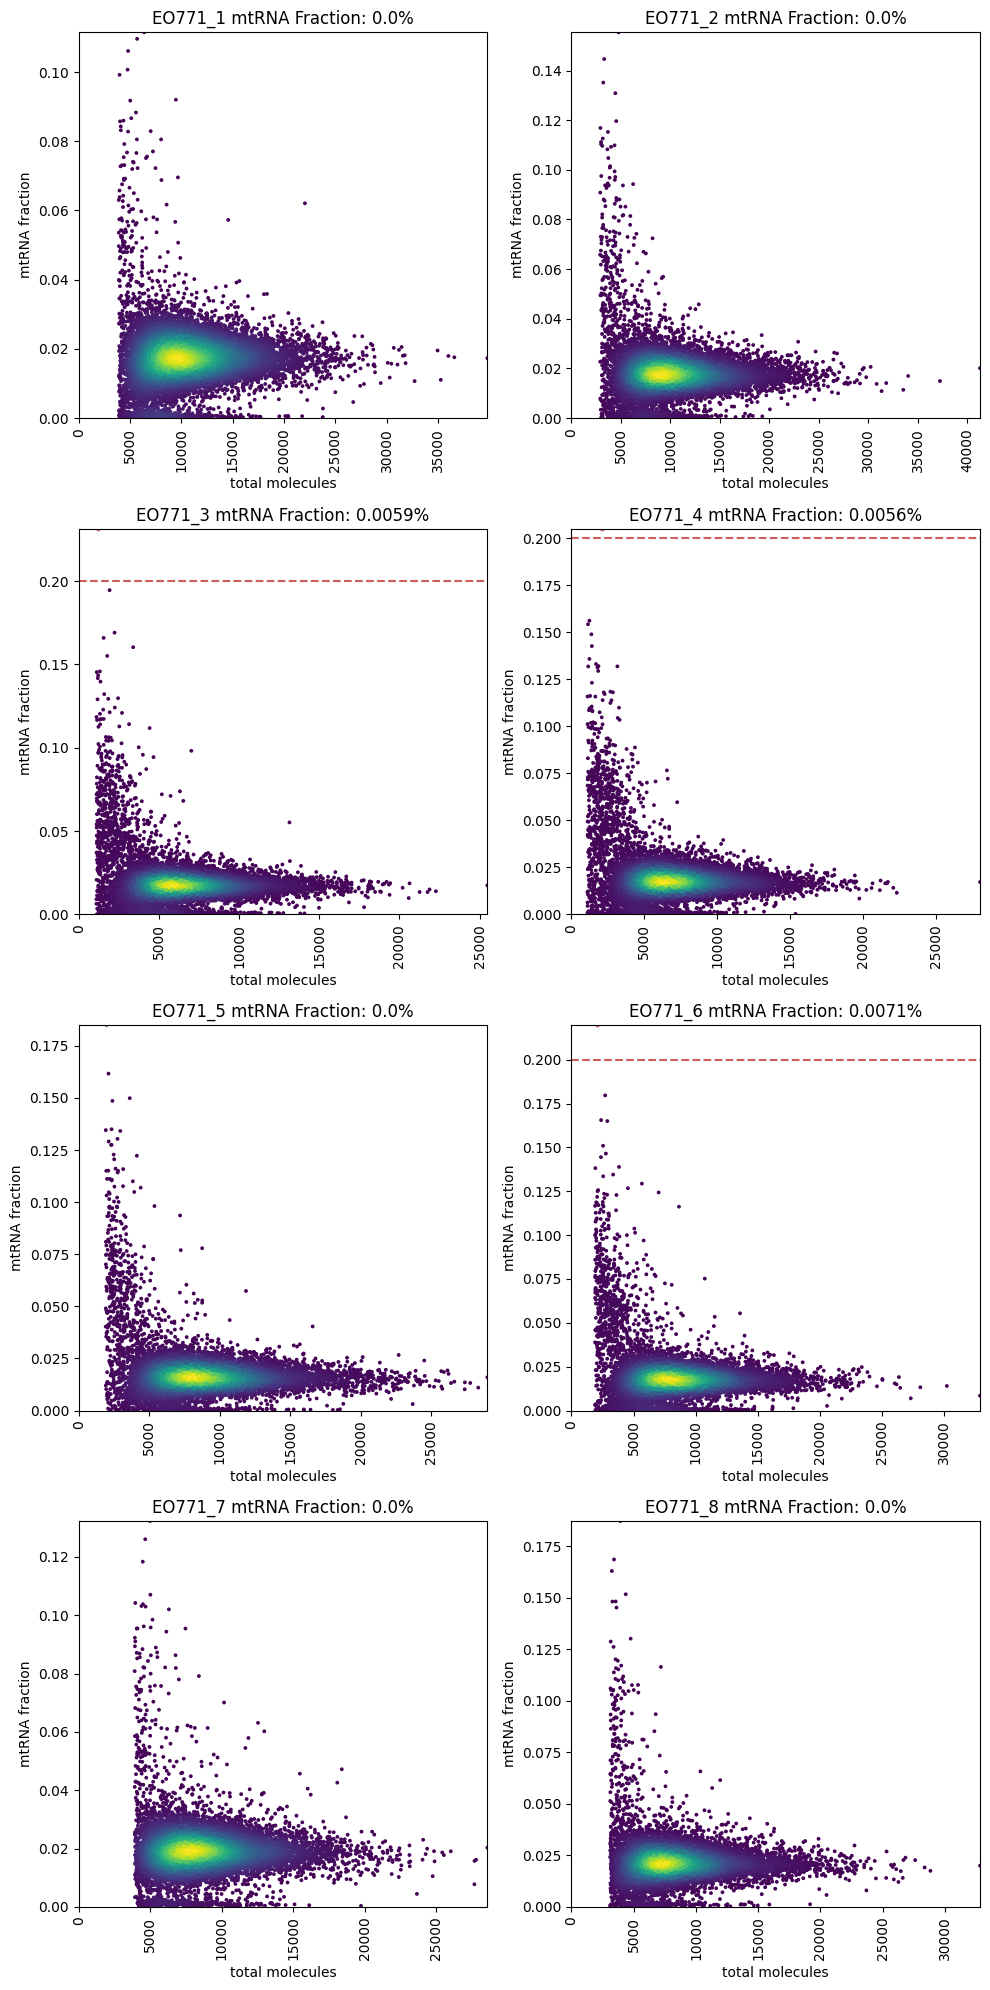

In [28]:
mito_thresh = 0.2
idx=1
fig = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
mt_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    mt_invalid[sample] = np.zeros(sum(f), bool)
    low_count_dict = {}
    molecules = coo_matrix(adata[f].X)
    mt_invalid[sample] = scrpr.filter_high_mitochondrial_rna(molecules, genes, mt_invalid[sample], 
                                                     max_mt_content=mito_thresh, plot=True, 
                                                     ax=ax, mt_prefix='mt-')
    print(f"Cells removed: {np.count_nonzero(mt_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(mt_invalid[sample]==0)}")
    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)
plt.savefig(f'{output_dir}/{run_name}_mtFilter.png', dpi=400)
plt.tight_layout()
plt.show()

### coverage filter

ymax=1.32881991459223
Cells removed: 7
Cells remaining: 14900
Cells failing this filter: 7
ymax=1.3681868743047831
Cells removed: 10
Cells remaining: 16766
Cells failing this filter: 10
ymax=1.3470380194518126
Cells removed: 21
Cells remaining: 16865
Cells failing this filter: 20
ymax=1.3141741071428572
Cells removed: 30
Cells remaining: 17963
Cells failing this filter: 29
ymax=1.3250919333385494
Cells removed: 20
Cells remaining: 14528
Cells failing this filter: 20
ymax=1.3262006657156442
Cells removed: 21
Cells remaining: 14117
Cells failing this filter: 20
ymax=1.3136064744562468
Cells removed: 11
Cells remaining: 13827
Cells failing this filter: 11
ymax=1.3119802894979982
Cells removed: 9
Cells remaining: 15029
Cells failing this filter: 9


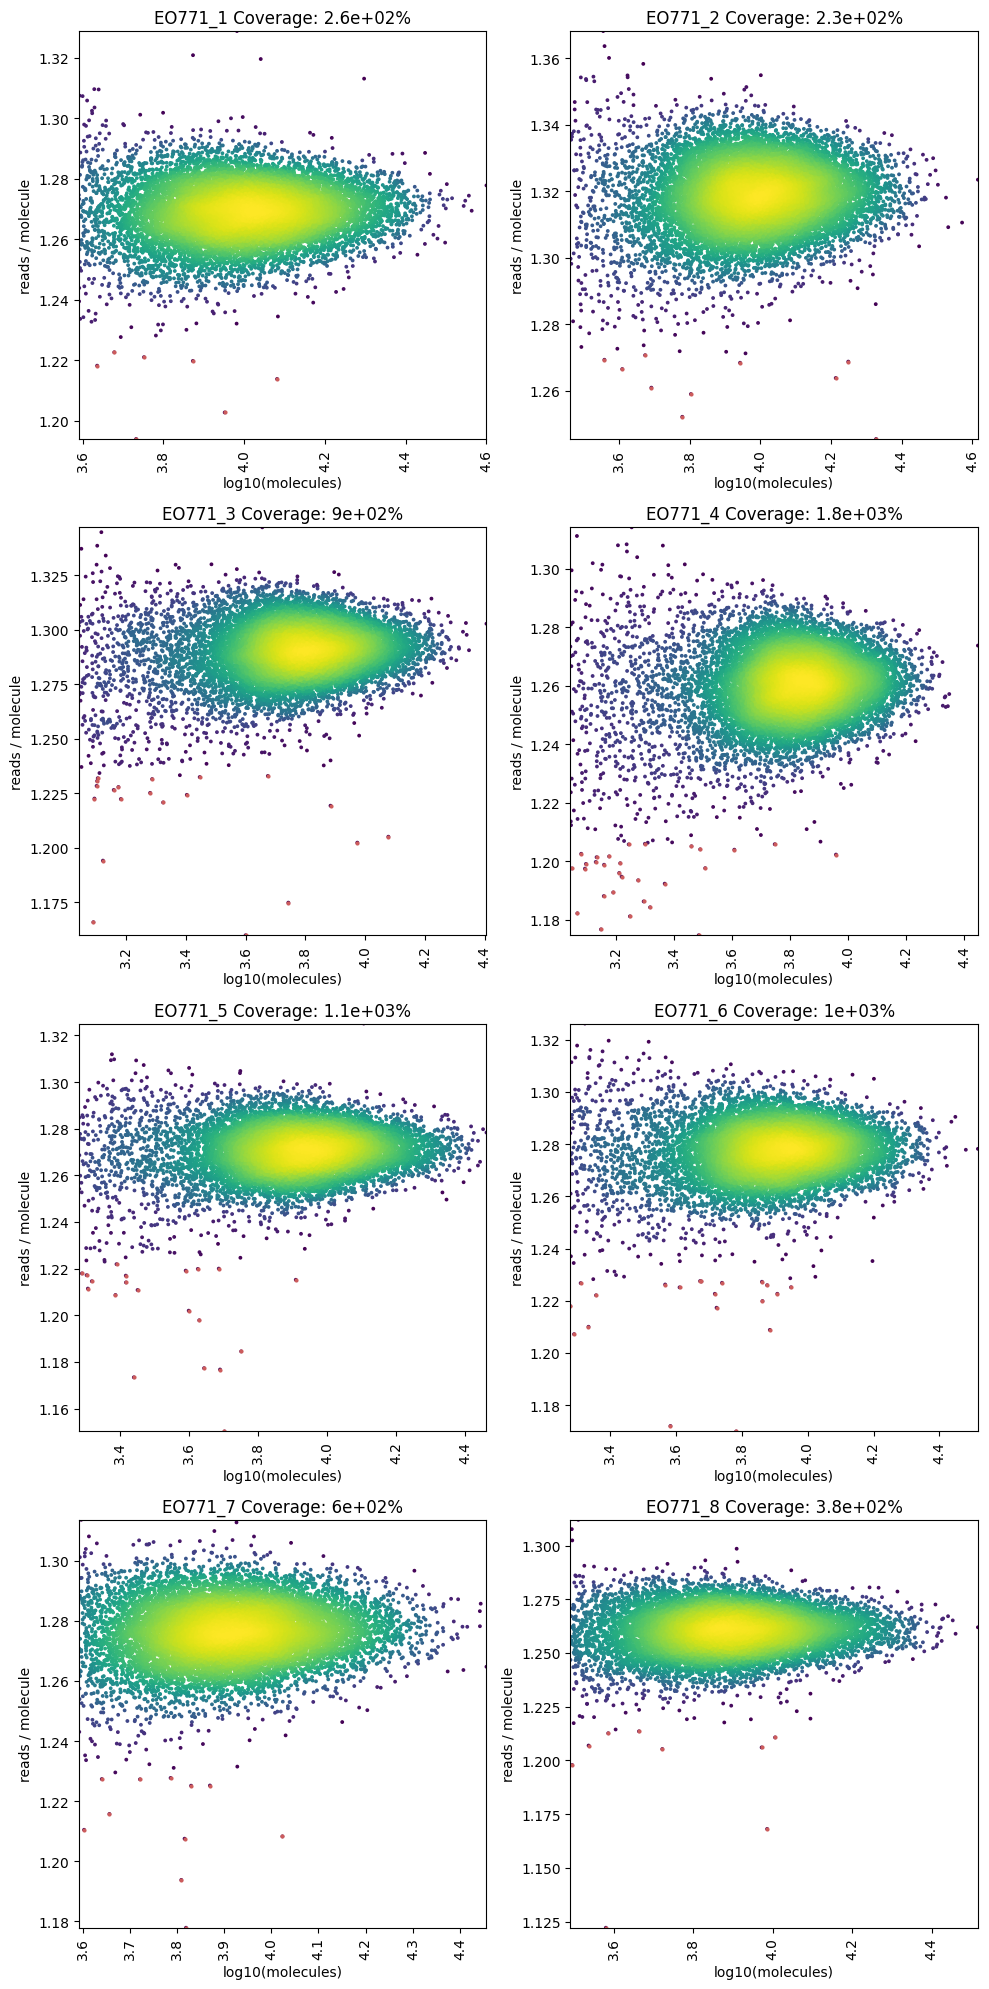

In [29]:
idx=1
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 5*nrows))
cov_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    molecules = coo_matrix(adata[f].X)
    cov_invalid[sample] = scrpr.filter_low_coverage(molecules, adata[f].layers['read_matrix'], 
                                                    mt_invalid[sample], cutoff=5, plot=True, ax = ax)
    print(f"Cells removed: {np.count_nonzero(cov_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(cov_invalid[sample]==0)}")
    print(f"Cells failing this filter: {sum(cov_invalid[sample]) - sum(mt_invalid[sample])}")
    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)

# SAVE FIGURE
fn = f'{output_dir}/{run_name}_readsPerMolecule_vs_size.png'
plt.tight_layout()
plt.savefig(fn, dpi=400)
plt.show()

### Complexity

In [30]:
is_invalid = {}
for sample in samples:
    is_invalid[sample] = (mt_invalid[sample] ) | (cov_invalid[sample])
    print(sample, sum(is_invalid[sample]))

EO771_1 7
EO771_2 10
EO771_3 21
EO771_4 30
EO771_5 20
EO771_6 21
EO771_7 11
EO771_8 9


Cells removed: 8
Cells remaining: 14899
Cells failing this filter: 1
Cells removed: 10
Cells remaining: 16766
Cells failing this filter: 0
Cells removed: 23
Cells remaining: 16863
Cells failing this filter: 2
Cells removed: 31
Cells remaining: 17962
Cells failing this filter: 1
Cells removed: 21
Cells remaining: 14527
Cells failing this filter: 1
Cells removed: 23
Cells remaining: 14115
Cells failing this filter: 2
Cells removed: 11
Cells remaining: 13827
Cells failing this filter: 0
Cells removed: 11
Cells remaining: 15027
Cells failing this filter: 2


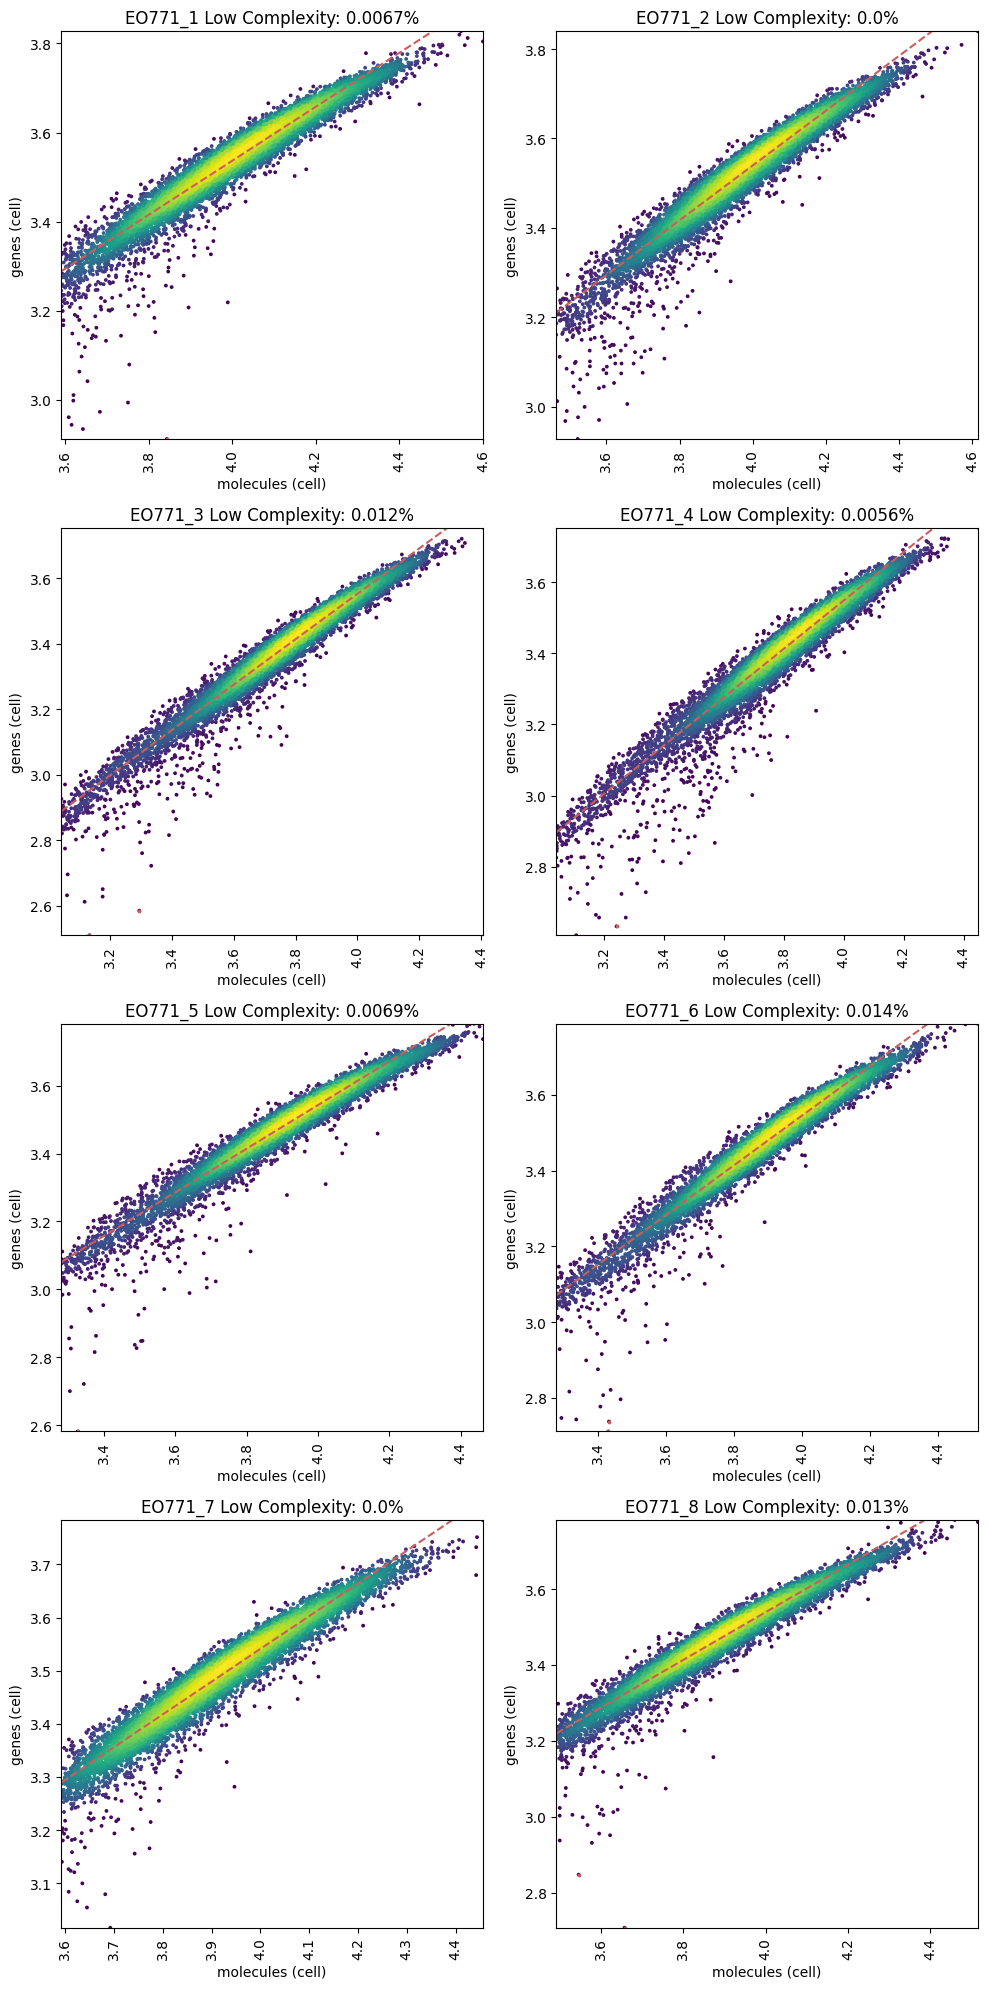

In [31]:
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 5*nrows))
idx = 1
complexity_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    molecules = coo_matrix(adata[f].X)
    complexity_invalid[sample] = scrpr.filter_low_gene_abundance(molecules, 
                                                         is_invalid[sample], residual_cutoff=0.40, plot=True, ax=ax)
    print(f"Cells removed: {np.count_nonzero(complexity_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(complexity_invalid[sample]==0)}")
    print(f"Cells failing this filter: {sum(complexity_invalid[sample]) - sum(is_invalid[sample])}")

    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)

fn = f'{output_dir}/{run_name}_complexityFilter.png'
plt.tight_layout()
plt.savefig(fn, dpi=400)
plt.show()

In [32]:
for sample in samples:
    is_invalid[sample] = (is_invalid[sample] ) | (complexity_invalid[sample])
    print(sample, sum(is_invalid[sample]))

EO771_1 8
EO771_2 10
EO771_3 23
EO771_4 31
EO771_5 21
EO771_6 23
EO771_7 11
EO771_8 11


In [33]:
all_invalid = np.zeros(adata.shape[0], bool)
for s in samples:
    f = (adata.obs['sample'] == s)
    all_invalid[f] = is_invalid[s]
adata = adata[~all_invalid]
adata.shape

(123986, 32245)

In [34]:
adata.obs['totReads'] = np.array(np.sum(adata[:,genes].layers['read_matrix'], axis=1)).reshape(-1)
adata.obs['library_size'] = np.squeeze(np.asarray(np.sum(adata[:,genes].X, axis=1)))
adata.layers['X_orig'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=10000)
adata.layers['X'] = adata.X.copy()
adata.X = adata.layers['X'].copy()

# note: next 3 lines are equivalent to adata.layers['logX'] = np.log10(adata.X+0.1)-np.log10(0.1) = np.log10(10x+1)
adata.X = adata.X*10
sc.pp.log1p(adata, base=10)
adata.layers['logX'] = adata.X.copy()
print(np.max(adata.layers['logX']), np.max(adata.layers['X']))

/tmp/ipykernel_10249/134937359.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['totReads'] = np.array(np.sum(adata[:,genes].layers['read_matrix'], axis=1)).reshape(-1)


4.829477 6752.5874


### Parse TWIST variation annotations from CellRanger

The CellRanger output can give us positional variants based on the TWIST barcode read from feature reads

In [35]:
adata

AnnData object with n_obs × n_vars = 123986 × 32245
    obs: 'sample', 'library_size', 'mt_frac', 'totReads'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'variants', 'log1p'
    obsm: 'variant_counts', 'variant_reads'
    layers: 'read_matrix', 'X_orig', 'X', 'logX'

In [36]:
# use reads to call variant, not UMIs
varcol = 'variant_reads'

In [37]:
adata.obs['numVariant'] = np.sum(adata.obsm[varcol] > 0, axis=1)

In [38]:
# most cells have small number of variants, but there is a long tail
adata.obs['numVariant'].value_counts()

numVariant
1      47005
2      29870
0      18590
3      14214
4       6331
       ...  
82         1
72         1
62         1
81         1
149        1
Name: count, Length: 70, dtype: int64

In [39]:
# assign maxvariant to most frequently observed variant in each cell
adata.obs['maxvariant'] = np.array(variants)[np.argmax(adata.obsm[varcol], axis=1)]
adata.obs.loc[adata.obs['numVariant'] == 0,'maxvariant'] = 'None'

In [40]:
# If two variants have equal numbers of reads, set variant to None
maxval = np.max(adata.obsm[varcol], axis=1)
adata.obs['variant_tied'] = False
adata.obs.loc[adata.obs['numVariant'] == 0,'variant_tied'] = True
for i,idx in enumerate(adata.obs.index):
    if adata.obs.loc[idx,'numVariant'] == 0:
        continue
    if sum(adata.obsm[varcol][i,:] == maxval[i]) > 1:
        adata.obs.loc[idx,'variant_tied'] = True
adata.obs.loc[adata.obs['variant_tied'],'maxvariant'] = 'None'
print(adata.obs['variant_tied'].value_counts())

variant_tied
False    100571
True      23415
Name: count, dtype: int64


In [41]:
# compute variant entropy per cell
adata.obs['entropy'] = 0.0
for i in adata.obs.index:
    tmp = np.array(adata[i].obsm[varcol]).reshape(-1)
    tmp = tmp[tmp > 0]/sum(tmp)
    if len(tmp) <= 1:
        continue
    adata.obs.loc[i,'entropy'] = -np.sum(tmp*np.log(tmp))/np.log(len(tmp))

In [42]:
adata.obs['numvariant_umis'] = np.sum(adata.obsm['variant_counts'], axis=1)
adata.obs['numvariant_reads'] = np.sum(adata.obsm['variant_reads'], axis=1)

Text(0.5, 1.0, 'all cells')

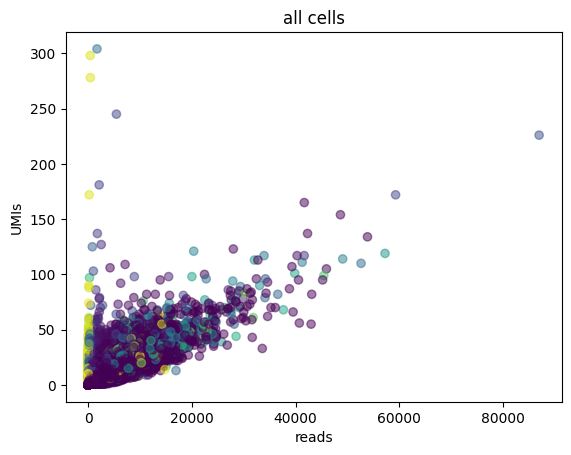

In [43]:
plt.scatter(adata.obs['numvariant_reads'],
            adata.obs['numvariant_umis'], c=adata.obs['entropy'], alpha=0.5)
plt.xlabel('reads')
plt.ylabel('UMIs')
plt.title('all cells')
#plt.xscale('log')
#plt.yscale('log')

Text(0.5, 1.0, 'cells with entropy < 0.7')

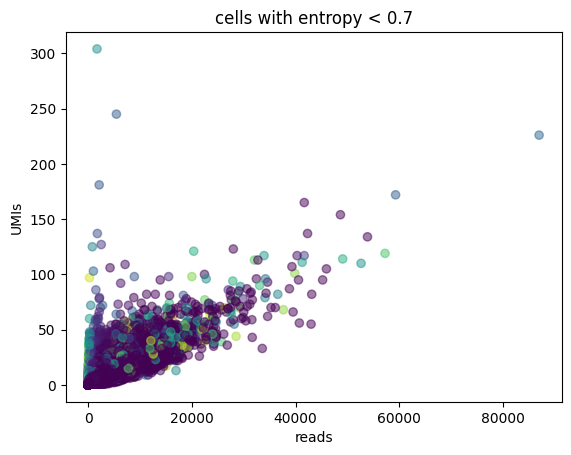

In [44]:
f = adata.obs['entropy'] < 0.7
plt.scatter(adata.obs.loc[f,'numvariant_reads'],
            adata.obs.loc[f,'numvariant_umis'], c=adata.obs.loc[f,'entropy'], alpha=0.5)
plt.xlabel('reads')
plt.ylabel('UMIs')
plt.title('cells with entropy < 0.7')
#plt.xscale('log')
#plt.yscale('log')

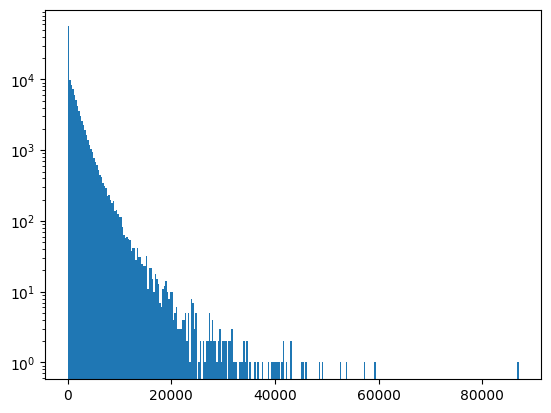

In [45]:
plt.hist(adata.obs['numvariant_reads'], bins=300)
plt.yscale('log')

Text(0, 0.5, 'count')

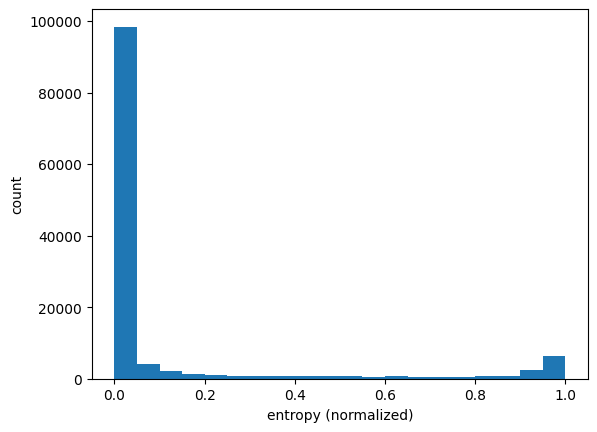

In [46]:
plt.hist(adata.obs['entropy'], bins=20)
plt.xlabel('entropy (normalized)')
plt.ylabel('count')

In [47]:
adata.obs.columns

Index(['sample', 'library_size', 'mt_frac', 'totReads', 'numVariant',
       'maxvariant', 'variant_tied', 'entropy', 'numvariant_umis',
       'numvariant_reads'],
      dtype='object')

In [48]:
f = (adata.obs['entropy'] < 0.7) & (adata.obs['variant_tied']==False) & (adata.obs['numvariant_umis'] > 0)
print(sum(f))
adata.obs['variant_cr'] = 'None'
adata.obs.loc[f,'variant_cr'] = adata.obs.loc[f,'maxvariant'].astype(str)

94376


In [49]:
adata.obs['variant_cr'].value_counts(normalize=False)

variant_cr
None         29610
mSTING_WT     4289
STOP          2808
V143X          931
L26X           747
             ...  
S130X            8
G206X            8
L189X            7
L264X            2
H156X            1
Name: count, Length: 387, dtype: int64

In [50]:
adata.obs.loc[adata.obs['variant_cr'] != 'None', 'sample'].value_counts()

sample
EO771_4    13515
EO771_2    13176
EO771_3    12819
EO771_8    11577
EO771_5    11147
EO771_1    10921
EO771_7    10726
EO771_6    10495
Name: count, dtype: int64

__Fix errors in feature_ref_v2 file__

The v2 vesrion has dUPR and dCTT flipped, and also calls A261X mutation just 261X. If cellranger was run with v3, this does not need to be run, so first detect the version (assuming all samples were mapped with same version)

In [51]:
if feature_ref_version == 'v2' or sum(adata.obs['variant_cr'] == '261X')!=0:
    # first, double-check. If features are named A261X, then this version was not used. Skip and write a warning.
    f = adata.obs['variant_cr'] == 'A261X'
    if sum(f) != 0:
        print('WARNING: feature_ref_version set to v2, but A261X variants detected; we think v3 was actually used. Skipping v2 corrections')
    else:
        if feature_ref_version != 'v2':
            print(f'WARNING: some variants have 261X variant, which was an error in twist_mSTING_full_feature_ref_v2.csv file. But feature_ref_version={feature_ref_version}.')
            print('Assuming version is actually v2 and applying the corrections')
        fdupr = adata.obs['variant_cr'] == 'dUPR'
        fdctt = adata.obs['variant_cr'] == 'dCTT'
        print(f'Switching {sum(fdupr)} dUPR variants to dCTT')
        print(f'Switching {sum(fdctt)} dCTT variants to dUPR')
        adata.obs.loc[fdupr,'variant_cr'] = 'dCTT'
        adata.obs.loc[fdctt,'variant_cr'] = 'dUPR'
        
        f = adata.obs['variant_cr'].isin(['dUPR', 'dCTT'])
        adata.obs.loc[f,'variant_cr'].astype(str).value_counts()
        
        # A261X was wrongly named 261X in original variant barcode file, fix
        adata.obs['variant_cr'] = adata.obs['variant_cr'].astype(str)
        f = adata.obs['variant_cr'] == '261X'
        print(f'Changing {sum(f)} 261X variants to A261X')
        adata.obs.loc[f, 'variant_cr'] = 'A261X'


Switching 125 dUPR variants to dCTT
Switching 146 dCTT variants to dUPR
Changing 163 261X variants to A261X


## Get clonal barcode

In [52]:
# return fractional distance between bc1 and bc2, correcting for N's 
def barcode_distance(bc1, bc2):
    numn1 = bc1.count('N')
    numn2 = bc2.count('N')
    ndiff = int(np.abs(numn1 - numn2))
    return editdistance.eval(bc1, bc2)-ndiff

In [53]:
os.getcwd()

'/data/satseq_processing/SatSeq_10x_Variant_Calling'

In [54]:
# This new version has dUPR/dCTT fixed and A261X fixed
twist=pd.read_csv('data/twist_mSTING_full_feature_ref_v3.csv', index_col=0)
twist

,name,read,pattern,sequence,feature_type
id,,,,,
SSBC0000,mSTING_WT,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),CGAGGAATTAGCAACG,Custom
SSBC0001,STOP,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GTAATGAATACCGAGG,Custom
SSBC0002,V146L,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),TGGCGGCGAATATAGC,Custom
SSBC0003,N153S,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),CCTCGAGAACTTTCCT,Custom
SSBC0004,V154M,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GGAATCAGACTGAAAC,Custom
...,...,...,...,...,...
T48BC374,R374X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GCTAACCAACTACCTC,Custom
T48BC375,T375X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),TGTAACATCCGTCGAA,Custom
T48BC376,D376X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GAGTTACTCATCGTCT,Custom


In [55]:
twistpos = twist.set_index('name', drop=True).copy()
twistpos['pos'] = 0
for i in twistpos.index:
    val=-5
    if i=='mSTING_WT':
        val=-5
    elif i=='STOP':
        val=-4
    elif i=='RRDD':
        val=-3
    elif i=='RRAA':
        val=-2
    elif i=='dCTT':
        val=-1
    elif i=='dUPR':
        val=0
    else:
        val=int(i[1:-1])
    twistpos.loc[i,'pos']=val
# add this entry
twistpos.loc['_379X','pos'] = 379

In [56]:
spikeIns = [x for x in twist['name'] if not x.endswith('X')]
spikeIns

['mSTING_WT',
 'STOP',
 'V146L',
 'N153S',
 'V154M',
 'S161A',
 'I229A',
 'Y239S',
 'N241A',
 'S365A',
 'RRAA',
 'RRDD',
 'dCTT',
 'dUPR']

In [57]:
nonPositionalSpikeIns=[x for x in twist['name'] if not x[1:-1].isnumeric()]
nonPositionalSpikeIns

['mSTING_WT', 'STOP', 'RRAA', 'RRDD', 'dCTT', 'dUPR']

In [58]:
# Read in consensus barcode for each cell
barcoderef='AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNCGCTNNNNNNNNNNNNNNNNCGCTTTAAGGCCGGTCCTAGCAA'
adata.obs['consensus_barcode'] = ''
adata.obs['consensus_barcode_twist'] = ''
for s in adata.obs['sample'].unique():
    fname=cellranger_out_dir + '/' + s  + '/outs/barcode_consensus_simple_bothref.fa.gz'
    if not os.path.exists(fname):
        print(f'Error: {fname} not found')
        continue
    print(f'Reading barcodes from {fname}')
    suffix = '-' + adata.obs.loc[adata.obs['sample'] == s].index[0].split('-')[-1]    
    cellname=''
    not_found=0
    found=0
    found_twist=0
    num_good_align=0  
    with gzip.open(fname, 'rt') as f:
        for line in f:
            if line.startswith('>'):
                cell=line.strip()[1:] + suffix
            else:
                barcodeseq=line
                if barcodeseq[:20] == barcoderef[:20] and barcodeseq[56:76] == barcoderef[56:76]:
                    num_good_align=num_good_align+1
                cellbarcode = barcodeseq[20:56]
                if cell in adata.obs.index:
                    #if adata.obs.loc[cell,'consensus_barcode'] != '':
                    #    print(f'error {cell}')
                    adata.obs.loc[cell,'consensus_barcode'] = cellbarcode
                    found=found+1
                    f = twist['sequence'].str.contains(cellbarcode[20:36])
                    if sum(f) == 1:
                        found_twist=found_twist+1
                        adata.obs.loc[cell, 'consensus_barcode_twist'] = twist.loc[f,'name'].iloc[0]
                else:
                    not_found=not_found+1
    f = adata.obs['sample'] == s
    f2 = adata.obs['consensus_barcode'] != ''
    diffcall = ((adata.obs['consensus_barcode_twist'] != adata.obs['variant_cr']) & 
                (adata.obs['variant_cr'] != 'None') & 
                (adata.obs['consensus_barcode_twist'] != ''))

    print(f'num_found={found} found_twist={found_twist} not_found={not_found} num_good_align={num_good_align} frac_cells={sum(f & f2)/sum(f)} diffcalls={sum(diffcall)}')

Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_06_11/EO771/EO771_1/outs/barcode_consensus_simple_bothref.fa.gz
num_found=12846 found_twist=9962 not_found=82084 num_good_align=50218 frac_cells=0.8622055171488019 diffcalls=0
Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_06_11/EO771/EO771_2/outs/barcode_consensus_simple_bothref.fa.gz
num_found=15656 found_twist=11825 not_found=119100 num_good_align=86651 frac_cells=0.9337945842777049 diffcalls=0
Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_06_11/EO771/EO771_3/outs/barcode_consensus_simple_bothref.fa.gz
num_found=15275 found_twist=11473 not_found=105275 num_good_align=66682 frac_cells=0.9058293304868648 diffcalls=1
Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_06_11/EO771/EO771_4/outs/barcode_consensus_simple_bothref.fa.gz
num_found=15794 found_twist=12453 not_found=80777 num_good_align=53080 frac_cells=0.8793007460193742 diffcalls=2
Reading barcodes from /workdir/satseq/Laughney-

In [59]:
# This is the fraction of cells with a consensus barcode - for the rest, we will not be able to 
# assign a specific mutation
sum(adata.obs['consensus_barcode'] != '')/adata.obs.shape[0]

0.9081428548384495

In [60]:
# These are the cells where the last 16 bp of the barcode are a perfect match to one of the TWIST barcodes - it is assigned to TWIST variant
sum(adata.obs['consensus_barcode_twist'] != '')/adata.obs.shape[0]

0.6848273192134596

In [61]:
# Should see almost perfect agreement between variant called from conensus barcode TWIST sequence
# and variant called by cellranger
(sum(adata.obs['consensus_barcode_twist'] == adata.obs['variant_cr']))/(
    sum((adata.obs['consensus_barcode_twist']!='') & (adata.obs['variant_cr'] != 'None')))

0.9999288408169075

In [62]:
# Are there any exceptions ?
adata.obs.loc[(adata.obs['consensus_barcode_twist'] != '') & (adata.obs['consensus_barcode_twist'] != adata.obs['variant_cr']) & (adata.obs['variant_cr'] != 'None')]

,sample,library_size,mt_frac,totReads,numVariant,maxvariant,variant_tied,entropy,numvariant_umis,numvariant_reads,variant_cr,consensus_barcode,consensus_barcode_twist
CACGACCGTATGGGTA-1-2,EO771_3,9762.0,0.021307,12483,1,A48X,False,0.000000,3.0,403,A48X,NNTNGNTNNTNCNNNNNNNNAGGTGTTGCGACTCTT,L329X
AAGTTTGCAACTATGA-1-3,EO771_4,5856.0,0.021004,7429,1,R76X,False,0.000000,1.0,1,R76X,NNTNGNTNNTNCNNNNNNNNAGGTGTTGCGACTCTT,L329X
TCAATTGGTCCATACG-1-4,EO771_5,11107.0,0.019087,14181,3,E142X,False,0.537229,9.0,1350,E142X,CTCACATTTGGATATGCGCTATCTTATGGGAGTGTG,V85X
TGGATTGTCAGCAGAG-1-6,EO771_7,10978.0,0.000273,14178,1,E148X,False,0.000000,1.0,1,E148X,NNTNGNTNNTNCNNNNNNNNAGGTGTTGCGACTCTT,L329X
CATACTTCAAGCGTTG-1-7,EO771_8,10976.0,0.025966,13916,2,E142X,False,0.024684,8.0,2050,E142X,ACTCTTGTGTTAGACCCGCTCTGGGATATGATGCAT,K288X
TGGCCATAGCGAGTTC-1-7,EO771_8,6838.0,0.012577,8628,1,A176X,False,0.000000,3.0,319,A176X,NNTNGNTNNTNCNNNNNNNNAGGTGTTGCGACTCTT,L329X


## Map consensus barcode to pacbio variant map

In [63]:
# Set bcmapfile to the file output by pacbio parsing notebook

bcmap = pd.read_csv(bcmapfile, index_col=0,sep='\t')[['aa_mut', 'score', 'closest_variant', 'vardist']]
print(bcmap.shape)
if sum(bcmap['aa_mut'].isin(nonPositionalSpikeIns)) > 0:
    # spike-ins should be removed from map already
    print("error")

(524208, 4)


In [64]:
# Create fasta file with each barcode map
bcmapfa = bcmapfile.replace('.txt.gz', 'fa')
with open(bcmapfa, 'w') as outf:
    for bc in bcmap.index:
        call=bcmap.loc[bc,'aa_mut']
        outf.write(f'>{call}:{bc}\n{bc}\n')

In [65]:
!head -n 12 {bcmapfa} 

>L197P:AAAAAAAAAAAAGGACCGCTCGCCAAGATACTAAGC
AAAAAAAAAAAAGGACCGCTCGCCAAGATACTAAGC
>S242F:AAAAAAAAAACGGCGGCGCTGCATCAACGTGGACTT
AAAAAAAAAACGGCGGCGCTGCATCAACGTGGACTT
>Y260M:AAAAAAAAATTAAACACGCTACTAGCGACTATGTGG
AAAAAAAAATTAAACACGCTACTAGCGACTATGTGG
>M131E:AAAAAAAACGGACACGCGCTCAGTTGAACGGTCTAT
AAAAAAAACGGACACGCGCTCAGTTGAACGGTCTAT
>E259A:AAAAAAAAGAGGGCAGCGCTATCCTCGTCAAACAGG
AAAAAAAAGAGGGCAGCGCTATCCTCGTCAAACAGG
>E55W:AAAAAAAAGATGAGCGCGCTTTCTCCATAGGTTCCT
AAAAAAAAGATGAGCGCGCTTTCTCCATAGGTTCCT


### First get perfect matches

If the cell has exact barcode in barcode map, then assigning variant is easy. For the rest we will do alignment with mmseqs2

In [66]:
bcmap

,aa_mut,score,closest_variant,vardist
bc,,,,
AAAAAAAAAAAAGGACCGCTCGCCAAGATACTAAGC,L197P,100.000000,L197X,0.0
AAAAAAAAAACGGCGGCGCTGCATCAACGTGGACTT,S242F,100.301030,S242X,0.0
AAAAAAAAATTAAACACGCTACTAGCGACTATGTGG,Y260M,100.000000,Y260X,0.0
AAAAAAAACGGACACGCGCTCAGTTGAACGGTCTAT,M131E,100.778151,M180X,0.0
AAAAAAAAGAGGGCAGCGCTATCCTCGTCAAACAGG,E259A,100.107970,E259X,0.0
...,...,...,...,...
TTTTTTTTTTACGTTTCGCTCGATCCTCCGTCAAAC,L51P,902.063880,L51X,0.0
TTTTTTTTTTAGTTGTCGCTATCCTCGCCCAAGTAT,P40V,100.000000,P40X,0.0
TTTTTTTTTTATCGCGCGCTACTCTCTCTTCCGTCA,A253T,100.000000,A253X,0.0


In [67]:
adata.obs.columns

Index(['sample', 'library_size', 'mt_frac', 'totReads', 'numVariant',
       'maxvariant', 'variant_tied', 'entropy', 'numvariant_umis',
       'numvariant_reads', 'variant_cr', 'consensus_barcode',
       'consensus_barcode_twist'],
      dtype='object')

In [68]:
adata.shape

(123986, 32245)

In [69]:
# merge bcmap with adata - only perfect matches will merge - this just prints the merge
adata.obs.reset_index().rename(columns={'index':'cell'}
                                    ).merge(bcmap, left_on='consensus_barcode',right_index=True)

,cell,sample,library_size,mt_frac,totReads,numVariant,maxvariant,variant_tied,entropy,numvariant_umis,numvariant_reads,variant_cr,consensus_barcode,consensus_barcode_twist,aa_mut,score,closest_variant,vardist
0,AAACCAAAGCGGACTT-1-0,EO771_1,11896.0,0.020847,15184,1,Y106X,False,0.000000,2.0,838,Y106X,TGAACTTGCTTTAATCCGCTTCATCGTCCCAAGCCA,Y106X,Y106A,902.125685,Y106X,0.0
2,AAACCATTCACCTCAT-1-0,EO771_1,13015.0,0.018210,16279,1,I10X,False,0.000000,3.0,421,I10X,CTTAGATTGTCCATAACGCTCCGTAATTTGCGCCGT,I10X,R76W,902.839091,I10X,0.0
5,AAACCCGCAGGTTCGA-1-0,EO771_1,11782.0,0.015108,15102,1,P372X,False,0.000000,14.0,2382,P372X,CAATATATCTAGGAATCGCTGACTCTAATGCGTAAC,P372X,P372L,902.233036,P372X,0.0
7,AAACCCTGTTTACTGA-1-0,EO771_1,5168.0,0.017608,6578,1,K337X,False,0.000000,3.0,422,K337X,CGTTAAAGTTAGTTTCCGCTAAATCTTAACGACCGC,K337X,K337I,903.396799,K337X,0.0
8,AAACCCTGTTTGGGCC-1-0,EO771_1,9505.0,0.019884,12085,1,L200X,False,0.000000,10.0,1268,L200X,TGAAACTCAGAACTTTCGCTGTCGGAAATGCAAGAT,L200X,L200G,903.246522,L200X,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123975,TGTGTACGTCAGTAAG-1-7,EO771_8,7439.0,0.010889,9471,1,A274X,False,0.000000,3.0,139,A274X,CTTGCCCAATCGCATTCGCTTACCTATCAGAAGCGT,A274X,R76L,800.801274,A274X,0.0
123976,TGTGTACGTTAGGTTC-1-7,EO771_8,6406.0,0.025913,8138,1,N186X,False,0.000000,3.0,1036,N186X,TTTTGACTATCCTGCACGCTTCTTCTATTCCATCCC,N186X,N186I,901.113372,N186X,0.0
123979,TGTGTACGTTGCGATT-1-7,EO771_8,5950.0,0.021681,7439,1,Y313X,False,0.000000,2.0,400,Y313X,TTCGCAATGTTTGCCTCGCTTCAACCGTCCATTAAC,Y313X,K19W,502.455896,Y313X,0.0
123980,TGTGTTAGTGAACCGG-1-7,EO771_8,6137.0,0.025583,7770,1,L47X,False,0.000000,5.0,2728,L47X,GCAGGGGCGGAATATTCGCTTGCCTCGGGAATCAGA,L47X,G90D,902.758165,L47X,0.0


In [70]:
match_columns = ['cell', 'variant', 'variant2', 'twist_mut', 'twist_closest_dist', 'corrected_barcode', 'edist', 'edist_n']
tmp = adata.obs.reset_index().rename(columns={'index':'cell'}
                                    ).merge(bcmap, left_on='consensus_barcode',right_index=True)[[
    'cell', 'aa_mut', 'closest_variant', 'vardist', 'consensus_barcode']].rename(columns={'aa_mut':'variant',
                                                                                              'closest_variant':'twist_mut',
                                                                                              'vardist':'twist_closest_dist'})
tmp['variant2'] =[','.join([y[:-1]+'X' for y in x.split(',')]) for x in tmp['variant']]
tmp['corrected_barcode'] = tmp['consensus_barcode'].copy()
tmp['edist'] = 0
tmp['edist_n'] = 0
resolved_matches = tmp[match_columns]

In [71]:
# This fraction of cells has a consensus barcode, the rest we will not be able to map
f = adata.obs['consensus_barcode'] != ''
print(sum(f)/adata.obs.shape[0])

0.9081428548384495


In [72]:
# This fraction of mappable cells has a perfect match to pacbio map
resolved_matches.shape[0]/sum(f)

0.5611783617680756

In [73]:
resolved_matches.shape

(63187, 8)

In [74]:
# These are ones that we may be able to map if we look for close matches between cell barcodes and pacbio map
(adata.shape[0] - resolved_matches.shape[0]) - sum(adata.obs['consensus_barcode'] == '')

49410

In [75]:
!mkdir -p {output_dir}/NOBACKUP

In [76]:
havecell = (resolved_matches['cell'])
f = (~adata.obs.index.isin(havecell)) & (adata.obs['consensus_barcode'] != '')
print(sum(f)) # should match above
queryfa = f'{output_dir}/NOBACKUP/query_{run_name}.fa'
with open(queryfa, 'w') as outf:
    for i in adata.obs.loc[f].index:
        outf.write('>' + adata.obs.loc[i].name + '\n')
        outf.write(adata.obs.loc[i,'consensus_barcode'] + '\n')
        

49410


In [77]:
# use mmseqs to search for alignments between pacbio and 10x barcodes
t0 = time.time()
cmd=f'{mmseqs_executable} easy-search --strand 1 --comp-bias-corr 0 --mask 0 --mask-profile 0'
cmd += f' --min-aln-len 30 -c 0.8 -k 6 --search-type 3 {queryfa} {bcmapfa}'
cmd += f' {output_dir}/NOBACKUP/alnRes_{run_name}.m8 {output_dir}/NOBACKUP/tmp_{run_name}'
print(cmd)
!{cmd}
t1 = time.time()
print(f'alignment time={t1-t0:.1f}s')


/opt/mmseqs/bin/mmseqs easy-search --strand 1 --comp-bias-corr 0 --mask 0 --mask-profile 0 --min-aln-len 30 -c 0.8 -k 6 --search-type 3 output/02_10x_processing/NOBACKUP/query_EO771_tumor.fa ../SatSeq_Bulk_DNAseq_Analysis/assets/bcmap_EO771_2025_02_27fa output/02_10x_processing/NOBACKUP/alnRes_EO771_tumor.m8 output/02_10x_processing/NOBACKUP/tmp_EO771_tumor
Create directory output/02_10x_processing/NOBACKUP/tmp_EO771_tumor
easy-search --strand 1 --comp-bias-corr 0 --mask 0 --mask-profile 0 --min-aln-len 30 -c 0.8 -k 6 --search-type 3 output/02_10x_processing/NOBACKUP/query_EO771_tumor.fa ../SatSeq_Bulk_DNAseq_Analysis/assets/bcmap_EO771_2025_02_27fa output/02_10x_processing/NOBACKUP/alnRes_EO771_tumor.m8 output/02_10x_processing/NOBACKUP/tmp_EO771_tumor 

MMseqs Version:                        	8ef870f95af2a3ee474c2cdbb845f5f007fe5be6
Substitution matrix                    	aa:blosum62.out,nucl:nucleotide.out
Add backtrace                          	false
Alignment mode                 

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



[=================================================================] 100.00% 49.41K 1s 238ms    
Time for merging to aln: 0h 0m 0s 13ms
9309838 alignments calculated
176551 sequence pairs passed the thresholds (0.018964 of overall calculated)
3.573184 hits per query sequence
Time for processing: 0h 0m 1s 383ms
rmdb output/02_10x_processing/NOBACKUP/tmp_EO771_tumor/10970996932835878624/search_tmp/8140130317680586093/search/pref_0 -v 3 

Time for processing: 0h 0m 0s 18ms
rmdb output/02_10x_processing/NOBACKUP/tmp_EO771_tumor/10970996932835878624/search_tmp/8140130317680586093/search/aln_0 -v 3 

Time for processing: 0h 0m 0s 0ms
rmdb output/02_10x_processing/NOBACKUP/tmp_EO771_tumor/10970996932835878624/search_tmp/8140130317680586093/search/input_0 -v 3 

Time for processing: 0h 0m 0s 0ms
rmdb output/02_10x_processing/NOBACKUP/tmp_EO771_tumor/10970996932835878624/search_tmp/8140130317680586093/search/aln_merge -v 3 

Time for processing: 0h 0m 0s 0ms
offsetalignment output/02_10x_process

In [78]:
barcode_matches = pd.read_csv(f'{output_dir}/NOBACKUP/alnRes_{run_name}.m8', sep='\t')
print(f'barcode_matches.shape={barcode_matches.shape}')
barcode_matches.columns=['cell', 'tbc', 'perc', 'len', 'mismatch', 'gapopen', 'qstart', 'qend', 'tstart', 'tend', 'evalue', 'bitscore']            
#f = (barcode_matches['qstart'] > 5) | (barcode_matches['tstart'] > 5) | (barcode_matches['qend'] < 30) | (barcode_matches['tend'] < 30)
#barcode_matches = barcode_matches.loc[~f]
print(f'filter for qstart/tsrat/qend/tend, now barcode_matches.shape={barcode_matches.shape}')
barcode_matches['variant'] = [x.split(':')[0] for x in barcode_matches['tbc']]
barcode_matches['variant2'] = [','.join([y[:-1]+'X' for y in x.split(',')]) for x in barcode_matches['variant']]
barcode_matches['corrected_barcode'] = [x.split(':')[1] for x in barcode_matches['tbc']]
barcode_matches.drop(columns=['tbc'], inplace=True)

# add barcode map data
barcode_matches = barcode_matches.merge(bcmap, left_on='corrected_barcode', right_index=True, how='left').drop(columns=['aa_mut']).rename(columns={'closest_variant':'twist_mut',
                                                                                                                         'vardist':'twist_closest_dist'})

print(f'barcode_matches.shape={barcode_matches.shape}')

barcode_matches.shape=(176550, 12)
filter for qstart/tsrat/qend/tend, now barcode_matches.shape=(176550, 12)
barcode_matches.shape=(176550, 17)


Text(0, 0.5, 'count')

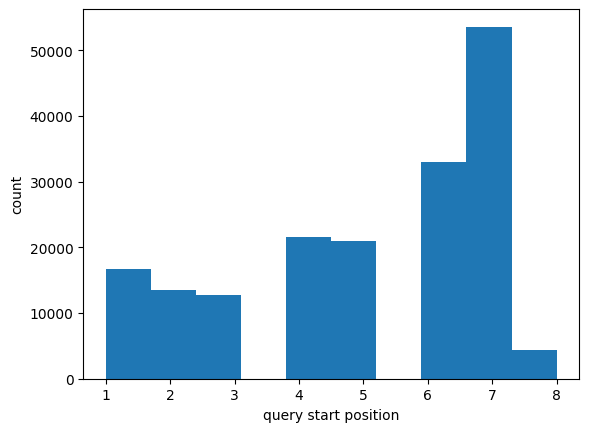

In [79]:
# What position in the barcode does the alignment start?
plt.hist(barcode_matches['qstart'])
plt.xlabel('query start position')
plt.ylabel('count')

In [80]:
# remove all but the best scores (keeping ties)
barcode_matches = barcode_matches.merge(barcode_matches[['cell', 'bitscore']].groupby('cell').max().reset_index(),
    left_on='cell', right_on='cell', suffixes=('', '_max')).sort_values(by=['cell', 'evalue'])
barcode_matches = barcode_matches.loc[barcode_matches['bitscore'] == barcode_matches['bitscore_max']].drop(columns='bitscore_max')
print(barcode_matches.shape[0], len(barcode_matches['cell'].unique()))

24318 19395


In [81]:
# compute edit distance for each alignment
# edist is number of edits
# edist_n is number of edits excluding Ns
barcode_matches['edist']=-1
for i in barcode_matches.index:
    barcode_matches.loc[i,'edist'] = editdistance.eval(adata.obs.loc[barcode_matches.loc[i,'cell'],'consensus_barcode'], barcode_matches.loc[i,'corrected_barcode'])
    barcode_matches.loc[i,'edist_n'] = barcode_distance(adata.obs.loc[barcode_matches.loc[i,'cell'],'consensus_barcode'], barcode_matches.loc[i,'corrected_barcode'])

In [82]:
# Add aligned cells to resolved_matches, which so far only contains perfect matches

# First add all cells that have a single entry, these are easiest. Remove these from the barcode_matches dataframe.
tmp = barcode_matches['cell'].value_counts()
goodCells = tmp[tmp==1].index
tmp=barcode_matches.loc[barcode_matches['cell'].isin(goodCells)].copy()
resolved_matches = pd.concat([resolved_matches, tmp[match_columns]])
barcode_matches = barcode_matches.loc[~barcode_matches['cell'].isin(goodCells)]
print(resolved_matches.shape[0], barcode_matches.shape[0])

79376 8129


In [83]:
# Now barcode_matches only contains tied mappings (by mrsearch alignment distance). Keep one with highest pacbio score:
maxcount = barcode_matches[['cell', 'score']].groupby('cell').max()
barcode_matches = barcode_matches.merge(maxcount, left_on='cell', right_index=True, suffixes=('','_max')).sort_values(by=['score'], ascending=False)
barcode_matches = barcode_matches.loc[barcode_matches['score'] == barcode_matches['score_max']]
tmp = barcode_matches['cell'].value_counts()
keepCell = list(tmp[tmp==1].index)
tmp = barcode_matches.loc[(~barcode_matches['cell'].duplicated()) & (barcode_matches['cell'].isin(keepCell))].copy()
resolved_matches = pd.concat([resolved_matches, tmp[match_columns]])
barcode_matches = barcode_matches.loc[~barcode_matches['cell'].isin(keepCell)]
print(resolved_matches.shape[0], barcode_matches.shape[0])

81680 1932


In [84]:
# Now everything in barcode_matches has multiple entries per cell with same alignment and pacbio scores.
# In some cases they may all point to the same mutation, so keep the one observed the most (if not tied)
mr1 = barcode_matches[['cell', 'variant']].value_counts().reset_index()
mrmax = mr1[['cell', 'count']].groupby('cell').max().reset_index()
mr1 = mr1.merge(mrmax, on='cell', suffixes=('', '_max'))
mr1 = mr1.loc[mr1['count'] == mr1['count_max']]
tmp = mr1['cell'].value_counts()
keepCells = tmp[tmp==1].index
mr1 = mr1.loc[mr1['cell'].isin(keepCells)]
tmp = barcode_matches[match_columns].merge(mr1[['cell', 'variant']], on=['cell', 'variant']).sort_values(by=['cell', 'twist_closest_dist'])
tmp = tmp[~tmp[['cell', 'variant']].duplicated()]
resolved_matches = pd.concat([resolved_matches, tmp])
barcode_matches = barcode_matches.loc[~barcode_matches['cell'].isin(keepCells)]
print(resolved_matches.shape[0], barcode_matches.shape[0])

81712 1862


In [85]:
# In some cases they disagree about exact mutation, but agree on position,
# so use variant2, which has resultant amino acid replaced with X
mr1 = barcode_matches[['cell', 'variant2']].value_counts().reset_index()
mrmax = mr1[['cell', 'count']].groupby('cell').max().reset_index()
mr1 = mr1.merge(mrmax, on='cell', suffixes=('', '_max'))
mr1 = mr1.loc[mr1['count'] == mr1['count_max']]
tmp = mr1['cell'].value_counts()
keepCells = tmp[tmp==1].index
mr1 = mr1.loc[mr1['cell'].isin(keepCells)]
tmp = barcode_matches[match_columns].merge(mr1[['cell', 'variant2']], on=['cell', 'variant2']).sort_values(by=['cell', 'twist_closest_dist'])
tmp = tmp[~tmp[['cell', 'variant2']].duplicated()]
tmp['variant'] = tmp['variant2']
resolved_matches = pd.concat([resolved_matches, tmp])
barcode_matches = barcode_matches.loc[~barcode_matches['cell'].isin(keepCells)]
print(resolved_matches.shape[0], barcode_matches.shape[0])

82276 622


In [86]:
# If an alignment is at position predicted by twist barcode, then keep it
f = (barcode_matches['variant'] == barcode_matches['twist_mut']) | (barcode_matches['variant2'] == barcode_matches['twist_mut'])
tmp = barcode_matches.loc[f,match_columns].copy()
tmp = tmp[~tmp.duplicated()]
tmpcount = tmp['cell'].value_counts()
dupcells = tmpcount[tmpcount > 1].index
tmp.loc[tmp['cell'].isin(dupcells),'variant'] = tmp.loc[tmp['cell'].isin(dupcells),'variant2']
tmp = tmp[~tmp['cell'].duplicated()]
keepCells = list(tmp['cell'])
resolved_matches = pd.concat([resolved_matches, tmp])
barcode_matches = barcode_matches.loc[~barcode_matches['cell'].isin(keepCells)]
print(resolved_matches.shape[0], barcode_matches.shape[0])

82527 110


In [87]:
# THese are the ones that we reduced to positional mutations 
print(sum(resolved_matches['variant'] == resolved_matches['variant2']))

6896


This is some data showing how many alignments I get using different -k options to mmseqs, using real data. Based on this, we use k=6 going forward
```
k=5 num=5446
k=6 num=5518
k=7 num=5410
k=8 num=5352
```

In [88]:
# Check: should not have any duplicate cells in resolved_matches
resolved_matches['cell'].value_counts()

cell
CAGGAGGCAGGAGCGA-1-6    1
AAACCAAAGCGGACTT-1-0    1
AAACCATTCACCTCAT-1-0    1
AAACCCGCAGGTTCGA-1-0    1
AAACCCTGTTTACTGA-1-0    1
                       ..
AAAGGTCAGCCTATCT-1-0    1
AAAGGTCAGGTCCAGT-1-0    1
AAAGGTCAGTAACGGG-1-0    1
AAAGGTTGTAGCAGTA-1-0    1
AAAGGTTGTCATGCTG-1-0    1
Name: count, Length: 82527, dtype: int64

In [89]:
resolved_matches = resolved_matches.set_index('cell', drop=True)

In [90]:
if 'variant_pacbio' in adata.obs.columns:
    print('dropping')
    adata.obs.drop(columns=[x for x in adata.obs.columns if x.endswith('_pacbio')], inplace=True, errors='ignore')

In [91]:
resolved_matches

,variant,variant2,twist_mut,twist_closest_dist,corrected_barcode,edist,edist_n
cell,,,,,,,
AAACCAAAGCGGACTT-1-0,Y106A,Y106X,Y106X,0.0,TGAACTTGCTTTAATCCGCTTCATCGTCCCAAGCCA,0,0.0
AAACCATTCACCTCAT-1-0,R76W,R76X,I10X,0.0,CTTAGATTGTCCATAACGCTCCGTAATTTGCGCCGT,0,0.0
AAACCCGCAGGTTCGA-1-0,P372L,P372X,P372X,0.0,CAATATATCTAGGAATCGCTGACTCTAATGCGTAAC,0,0.0
AAACCCTGTTTACTGA-1-0,K337I,K337X,K337X,0.0,CGTTAAAGTTAGTTTCCGCTAAATCTTAACGACCGC,0,0.0
AAACCCTGTTTGGGCC-1-0,L200G,L200X,L200X,0.0,TGAAACTCAGAACTTTCGCTGTCGGAAATGCAAGAT,0,0.0
...,...,...,...,...,...,...,...
CATACCAAGCCTTCGC-1-3,M270T,M270X,M270X,2.0,ACGTGTAAACACGCACGCTGATTACTTGTCCTGGGA,9,9.0
CATACTGAGTTAGAGA-1-7,M270T,M270X,M270X,2.0,ACGTGTAAACACGCACGCTGATTACTTGTCCTGGGA,9,9.0
CAGCAGCCAGCTATCC-1-4,E339V,E339X,E339X,0.0,TTAGTTGATCGGAACACGCTTGGTTAGCTGGTCATC,6,6.0


In [92]:
resolved_matches.shape

(82527, 7)

In [93]:
adata.obs.shape

(123986, 13)

In [94]:
# add resolved_matches to adata.obsb
adata.obs = adata.obs.join(resolved_matches.drop(columns=['variant2']).add_suffix('_pacbio'))

In [95]:
adata.obs

,sample,library_size,mt_frac,totReads,numVariant,maxvariant,variant_tied,entropy,numvariant_umis,numvariant_reads,variant_cr,consensus_barcode,consensus_barcode_twist,variant_pacbio,twist_mut_pacbio,twist_closest_dist_pacbio,corrected_barcode_pacbio,edist_pacbio,edist_n_pacbio
AAACCAAAGCGGACTT-1-0,EO771_1,11896.0,0.020847,15184,1,Y106X,False,0.000000,2.0,838,Y106X,TGAACTTGCTTTAATCCGCTTCATCGTCCCAAGCCA,Y106X,Y106A,Y106X,0.0,TGAACTTGCTTTAATCCGCTTCATCGTCCCAAGCCA,0.0,0.0
AAACCATTCACATTCC-1-0,EO771_1,9126.0,0.029257,11594,1,D300X,False,0.000000,2.0,476,D300X,CATGTGGTCCTCGATACGCTCACAGGTAAATGGCAC,D300X,D300P,D300X,0.0,GGCTTGTGGTCTTCTACGCTCACAGGTAAATGGCAC,6.0,6.0
AAACCATTCACCTCAT-1-0,EO771_1,13015.0,0.018210,16279,1,I10X,False,0.000000,3.0,421,I10X,CTTAGATTGTCCATAACGCTCCGTAATTTGCGCCGT,I10X,R76W,I10X,0.0,CTTAGATTGTCCATAACGCTCCGTAATTTGCGCCGT,0.0,0.0
AAACCATTCCCCTTGA-1-0,EO771_1,7002.0,0.017852,8979,0,None,True,0.000000,0.0,0,None,,,NaN,NaN,NaN,NaN,NaN,NaN
AAACCCGCAAGCCGAC-1-0,EO771_1,7845.0,0.014532,10043,1,P302X,False,0.000000,1.0,45,P302X,TTAGTTTACCGTCGAGCGCTGTCTCTACTCTGTGAC,P302X,P302Y,P302X,0.0,TTAGTTTTCCGACGACCGCTGTCTCTACTCTGTGAC,3.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TGTGTTAGTGATGCCC-1-7,EO771_8,12759.0,0.024532,16059,2,N217X,False,0.005815,10.0,2152,N217X,CTTGGCTACGGGCTCGCGCTTCAGACCCAAATCGAG,N217X,N217Q,N217X,0.0,CTTGGCTACGGGCTCGCGCTTCAGACCCAAATCGAG,0.0,0.0
TGTGTTAGTTCCAGGC-1-7,EO771_8,5099.0,0.015493,6436,1,A141X,False,0.000000,1.0,2,A141X,ANNNNNNANNNNNNNNNNNNAANNNNNNNNNNNNNN,,NaN,NaN,NaN,NaN,NaN,NaN
TGTGTTAGTTCGATAC-1-7,EO771_8,6479.0,0.019447,8287,3,R374X,False,0.016939,5.0,1234,R374X,NCGNTNNNNNNNNTNNCNNNGCTANNNANNTNNNNN,,NaN,NaN,NaN,NaN,NaN,NaN
TGTGTTAGTTGCATTA-1-7,EO771_8,4850.0,0.041856,6154,1,M180X,False,0.000000,1.0,1,M180X,NNNNNNNNNNNNNNNNCGCNNNTCNGNTNNNNNGTN,,NaN,NaN,NaN,NaN,NaN,NaN


Text(0, 0.5, 'count')

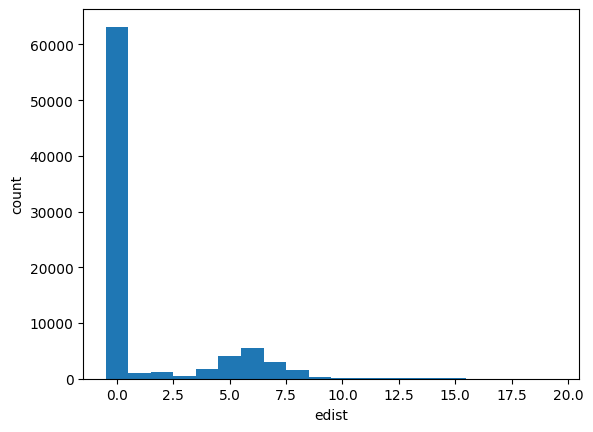

In [96]:
# Most barcodes are perfect match, the mmseqs alignment process only added info to a few cells
# (with edist > 0)
plt.hist(adata.obs['edist_pacbio'], bins=np.arange(-0.5, 20.5, 1))
plt.xlabel('edist')
plt.ylabel('count')

Text(0, 0.5, 'count')

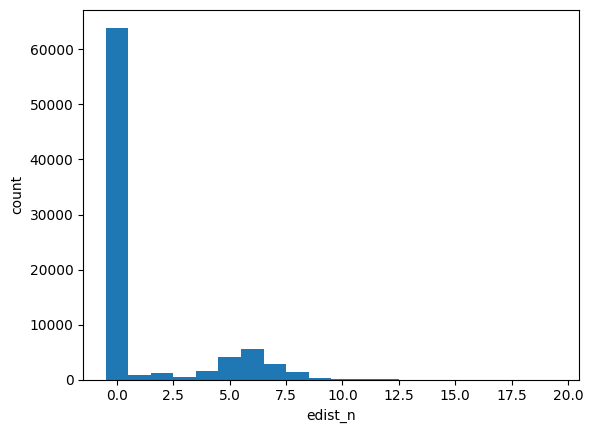

In [97]:
plt.hist(adata.obs['edist_n_pacbio'], bins=np.arange(-0.5, 20.5, 1))
plt.xlabel('edist_n')
plt.ylabel('count')

In [98]:
# This filter allows 2 mismatches (edist_n) and up to 4 N's
f = (~pd.isna(adata.obs['edist_pacbio'])) & (adata.obs['edist_pacbio'] <= 5)
#f1 = (f) & (adata.obs['edist_pacbio'] <= 6)
#f2 = (f) & (adata.obs['edist_n_pacbio'] <= 4)
#print(sum(f1), sum(f2), sum(f1 & f2))
#adata.obs.loc[~(f1 & f2),'variant_pacbio'] = 'None'
print(sum(~f))
adata.obs.loc[~f,'variant_pacbio'] = 'None'
print(sum(adata.obs['variant_pacbio'] == 'None'), sum(adata.obs['variant_pacbio'] != 'None'))

52283
52283 71703


In [99]:
# There are a few cells that get mapped to positional variant with pacbio map but where cellranger assigned to non-positional spike-in. 
# Need to look at these and decide what to do. Should be small number.
# in this case the edists are all small, I will keep the pacbio calls
f2 = (adata.obs['variant_pacbio'] != 'None') & (adata.obs['variant_cr']).isin(nonPositionalSpikeIns)
adata.obs.loc[f2, ['variant_cr', 'variant_pacbio', 'edist_pacbio', 'edist_n_pacbio']]

,variant_cr,variant_pacbio,edist_pacbio,edist_n_pacbio
CGCTGCAAGGTGAGTG-1-0,STOP,A350Y,2.0,2.0
GGTATCGCATCACGGA-1-0,STOP,A48Q,3.0,3.0
TCCTTTGGTCATTCCC-1-0,RRDD,V355N,2.0,2.0
AAGCCATCAGGTAATC-1-1,mSTING_WT,L63Q,2.0,2.0
ACGGACAAGGATGGTG-1-1,mSTING_WT,H185Q,2.0,2.0
ACTCGTCCACTCATCA-1-1,STOP,G366W,5.0,5.0
ATCAGGGAGCGACTTA-1-1,mSTING_WT,N186R,4.0,4.0
GCGAGTTTCACTTGGA-1-1,STOP,G366W,5.0,5.0
GTGTAAGGTGCGAGCA-1-1,mSTING_WT,Q272X,2.0,2.0
AAACTTGCATGGCAGC-1-2,mSTING_WT,I229A,4.0,4.0


In [100]:
adata.obs['variant'] = adata.obs['variant_pacbio'].copy()
f = (adata.obs['variant'] == 'None') & (adata.obs['variant_cr'] != 'None')
f2 = (f) & (adata.obs['variant_cr'].isin(nonPositionalSpikeIns))
print(f'{sum(f)} cells do not have pacbio variant but do have call from cellranger, {sum(f2)} are non-positional spike-ins. Using cellranger calls for these cells')
adata.obs.loc[f,'variant'] = adata.obs.loc[f,'variant_cr'].copy()
adata.obs.loc[f,'variant_cr'].value_counts().iloc[:10]

24189 cells do not have pacbio variant but do have call from cellranger, 7525 are non-positional spike-ins. Using cellranger calls for these cells


variant_cr
mSTING_WT    4266
STOP         2797
S103X         213
V143X         201
M270X         170
K83X          155
R219X         153
A145X         152
L362X         150
C95X          147
Name: count, dtype: int64

In [101]:
adata.obs['variant'].value_counts()

variant
None         28094
mSTING_WT     4266
STOP          2797
Y3X            351
C205Y          337
             ...  
L324E            1
A87T             1
Y163L            1
L44K             1
T341D            1
Name: count, Length: 5162, dtype: int64

In [102]:
adata.obs['variant'].value_counts(normalize=True)

variant
None         0.226590
mSTING_WT    0.034407
STOP         0.022559
Y3X          0.002831
C205Y        0.002718
               ...   
L324E        0.000008
A87T         0.000008
Y163L        0.000008
L44K         0.000008
T341D        0.000008
Name: proportion, Length: 5162, dtype: float64

In [103]:
# given aa mut, return same value but with new AA replaced with X.
# if double mutation replace both
# if special mutation leave as is
def get_aamut_pos_str(aa_mut):
    if ',' in aa_mut:
        tmp = aa_mut.split(',')
        retval = []
        for t in tmp:
            retval.append(get_aamut_pos_str(t))
        return ','.join(retval)
    if aa_mut in list(twist['name']):
        return aa_mut
    tmp = aa_mut[:-1]+'X'
    if tmp not in list(twist['name']) and '_379' not in tmp:
        print(f'error {aa_mut}')
        return None
    return tmp 

In [104]:
adata.obs['variant_pos'] = 'None'
f = adata.obs['variant'] != 'None'
adata.obs.loc[f,'variant_pos'] = [get_aamut_pos_str(x) for x in adata.obs.loc[f,'variant']]

In [105]:
adata

AnnData object with n_obs × n_vars = 123986 × 32245
    obs: 'sample', 'library_size', 'mt_frac', 'totReads', 'numVariant', 'maxvariant', 'variant_tied', 'entropy', 'numvariant_umis', 'numvariant_reads', 'variant_cr', 'consensus_barcode', 'consensus_barcode_twist', 'variant_pacbio', 'twist_mut_pacbio', 'twist_closest_dist_pacbio', 'corrected_barcode_pacbio', 'edist_pacbio', 'edist_n_pacbio', 'variant', 'variant_pos'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'variants', 'log1p'
    obsm: 'variant_counts', 'variant_reads'
    layers: 'read_matrix', 'X_orig', 'X', 'logX'

In [106]:
adata.obs['variant_full'] = adata.obs['variant'].copy()
adata.obs['variant'] = adata.obs['variant_pos'].copy()

In [107]:
f = adata.obs['variant_full'] != 'None'
adata.obs['variant'] = adata.obs['variant'].astype(str)
adata.obs.loc[f,'variant'] = [get_aamut_pos_str(x) for x in adata.obs.loc[f,'variant_full']]

In [108]:
f = pd.isna(adata.obs['corrected_barcode_pacbio'])
adata.obs.loc[f,'corrected_barcode_pacbio'] = adata.obs.loc[f,'consensus_barcode'].copy()

## Combine similar clonal barcodes within variant groups

To get clonal groups, want to combine cells with very close clonal barcode and same AA mutation

These were ultimately not used in satseq paper, but can distinguish whether cells with same observed mutation came from same clonal group

On demo data, there may not be many groups.

In [109]:
# within all cells with the same variant call, enumerate all observed barcodes
# get distance between all pairs. Do not count columns where either barcode has an N when computing distance.
# if distance is less than 10%, merge less common barcode with more common barcode
# repeat until no merges occur
def combine_clones(variant, varcol='variant_full', verbose=False, maxround=20):
    fbc = (adata.obs[varcol] == variant) & (adata.obs['corrected_barcode_pacbio'] != '')
    if (verbose):
        print(f'number of cells: {sum(fbc)}')
    if variant == 'None' or variant=='':
        return (variant, 0, 0, adata.obs.loc[fbc,'corrected_barcode_pacbio'].copy())
    numround=0
    newbc = adata.obs.loc[fbc, 'corrected_barcode_pacbio'].copy()
    if (verbose):
        print(f'newbc.shape={newbc.shape}')
    total_numfix=0
    while True:
        if verbose:
            print(f'Round {numround}')
        origbc = newbc.copy()
        bcs = origbc.astype(str).value_counts()
        bcmat = pd.DataFrame(1.0, index=[str(x) for x in bcs.index], columns=[str(x) for x in bcs.index])
        if verbose:
            print(f'bcmat.shape={bcmat.shape}')
        for spos, bc1 in enumerate(bcs.index[:-1]):
            for bc2 in bcs.index[spos:]:
                bcmat.loc[bc1,bc2] = barcode_distance(bc1, bc2)/len(bc1)
        numfix=0
        cutoff = 0.1
        for i in bcmat.index:
            f = (bcmat.loc[i] > 0) & (bcmat.loc[i] < cutoff)
            if sum(f) == 0:
                continue
            for j in bcmat.index[f]:
                f2 = origbc == j
                if sum(f2) > 0:
                    newbc[f2] = i
                    if verbose:
                        print(f'combining variant {i} {j} dist={bcmat.loc[i,j]*len(bc1)}')
                    numfix=numfix+1
        total_numfix += numfix
        numround=numround+1
        if numfix == 0:
            break
        if numround > maxround:
            break
    if verbose:
        print(f'Done numfix={total_numfix} numround={numround}')
    return (variant,total_numfix,numround,newbc)

In [110]:
adata.obs['variant_full'].astype(str).value_counts()

variant_full
None         28094
mSTING_WT     4266
STOP          2797
Y3X            351
C205Y          337
             ...  
L324E            1
A87T             1
Y163L            1
L44K             1
T341D            1
Name: count, Length: 5162, dtype: int64

In [111]:
results = []
adata.obs['clonal_barcode'] = adata.obs['corrected_barcode_pacbio'].astype(str).copy()
with multiprocessing.Pool(processes=50) as p:
    for tmp in  p.imap_unordered(combine_clones, adata.obs['variant_full'].unique()):
        f = (adata.obs['variant_full'] == tmp[0]) & (adata.obs['consensus_barcode'] != '')
        adata.obs.loc[f,'clonal_barcode'] = tmp[3]
        if tmp[1] > 1:
            print(f'{tmp[0]} numfix={tmp[1]} numround={tmp[2]}')

D300X numfix=9 numround=3
L70X numfix=21 numround=3
A9X numfix=40 numround=3
N228X numfix=58 numround=4
R12X numfix=97 numround=5
V35X numfix=99 numround=6
F268X numfix=57 numround=5
Q251X numfix=3 numround=2
H16X numfix=22 numround=3
R237X numfix=69 numround=5
S325X numfix=62 numround=3
P172X numfix=75 numround=6
S240X numfix=41 numround=3
P8X numfix=154 numround=6
P372X numfix=224 numround=8
Q314X numfix=5 numround=2
P316X numfix=80 numround=6
T341X numfix=22 numround=4
T43X numfix=87 numround=5
R17X numfix=198 numround=7
A145X numfix=90 numround=7
V238X numfix=6 numround=2
E339X numfix=77 numround=6
V85X numfix=96 numround=6
V21X numfix=155 numround=5
L174X numfix=223 numround=5
L324X numfix=403 numround=10
H72X numfix=290 numround=9
L116X numfix=9 numround=3
I99X numfix=185 numround=5
P225X numfix=156 numround=7
G15X numfix=52 numround=4
I234X numfix=170 numround=4
S354X numfix=36 numround=5
S128X numfix=46 numround=4
L362X numfix=310 numround=7
E55X numfix=128 numround=3
L371X num

In [112]:
# These are top groups of cells with same barcode
adata.obs[['corrected_barcode_pacbio','variant_pacbio']].value_counts().iloc[:20]

corrected_barcode_pacbio              variant_pacbio
                                      None              11389
NNNNNNNNNNNNNNNNCGCTNNNNNNNNNNNNNNNN  None                810
CACTTGGGGGAGTGTTCGCTCGCTTAAGGTGAGGTG  C205Y               337
CTAGCCCACAAAGACTCGCTTTCAAGCCGGTGTTCC  F25X                219
TTTTTTTAACGTGATTCGCTGACGTAGGGACAATCT  R292Y               204
ATTGACGTATAATTTGCGCTAACTGTTATGTCTCCG  A141Q               204
ACTCTCTCATGTGTCTCGCTCCGTACTGTTTCACAC  Y3X                 201
GCACGAGTACCTGAGGCGCTACTTGTGCCGAGTCAT  L26W                196
ACAAAGAGCCTGCGGTCGCTCTACAGTAAACGCCTT  I99X                174
GGCTATATAAGATATGCGCTACCTGCTCCATATTCA  Y46I                147
TCTGTTGATACAAACACGCTCACACGTTGGGAGCTT  L56Q                141
TTGAAGTAGCAGACCCCGCTCGACAAGAAGAGAATC  L203N               136
GTTAGCGTTTCCGTAAAGAACGAGGAATTAGCAACG  None                135
CTTTCCGTTTTCGATCCGCTGGTTGTACGGTCACAT  R196C               134
ACAAGTGCCTATCGTTCGCTTCCGGCTATATGTTTC  A48Q                134
GTTATGACATCCGGTAC

extracting highly variable genes


/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to r

    finished (0:00:11)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:508: FutureWarning: The provided callable <function nanmean at 0x7f99540e1ea0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  df = df.groupby("gene").agg(
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:508: FutureWarning: The provided callable <function nanmean at 0x7f99540e1ea0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  df = df.groupby("gene").agg(
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:508: FutureWarning: The provided callable <function nansum at 0x7f99540e1a20> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will b

Found 3968 highly variable genes


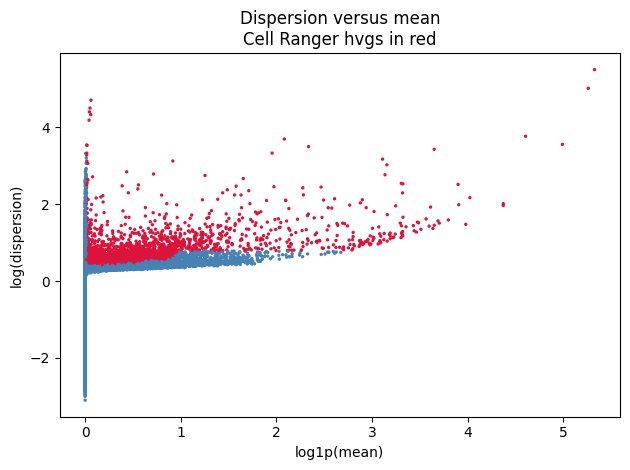

In [113]:
boolean_to_color = {True:'crimson',False:'steelblue'}
sc.settings.verbosity=4
adata.var.drop(columns=['highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatch', 'highly_variable_intersection'],
              inplace=True, errors='ignore')
sc.pp.highly_variable_genes(adata, flavor='cell_ranger', batch_key='sample', n_bins=20, max_mean=np.inf, layer='X')

colors_cell_ranger = [boolean_to_color[True] if x >0 else boolean_to_color[False]
                      for x in adata.var['highly_variable']]
plt.scatter(np.log1p(adata.var['means']), np.log(adata.var['dispersions']),
            s=2, c=colors_cell_ranger)
plt.xlabel('log1p(mean)')
plt.ylabel('log(dispersion)')
plt.title('Dispersion versus mean\nCell Ranger hvgs in red')
print(f'Found {sum(adata.var["highly_variable"])} highly variable genes')
fn = f'{output_dir}/{run_name}_hvgs_scanpy_cellranger_20bins_nomax.png'
plt.tight_layout()
plt.savefig(fn, dpi=400)
plt.show()
plt.close()

In [114]:
adata.X = adata.layers['logX']
sc.tl.pca(adata)

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:55)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PC1', 'PC2', ..., the loadings (adata.var)
    'pca_variance', the variance / eigenvalues (adata.uns)
    'pca_variance_ratio', the variance ratio (adata.uns)


In [115]:
np.max(adata.X)

4.829477

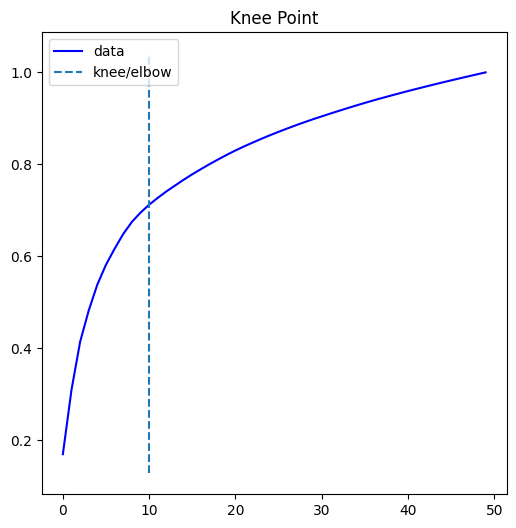

In [116]:
x = range(len(adata.uns['pca']['variance']))
y = np.cumsum(adata.uns['pca']['variance'])
y = y/np.max(y)
kneedle = KneeLocator(x, y)
kneedle.plot_knee()

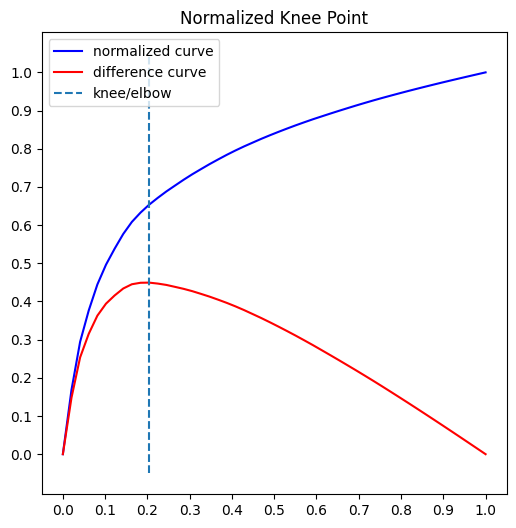

In [117]:
kneedle.plot_knee_normalized()

In [118]:
kneedle.knee

10

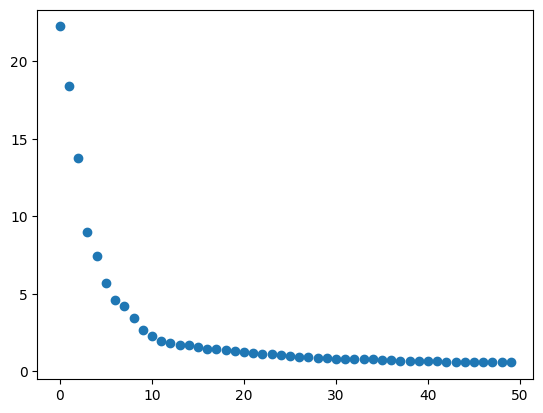

In [119]:
plt.scatter(range(50), adata.uns['pca']['variance'])

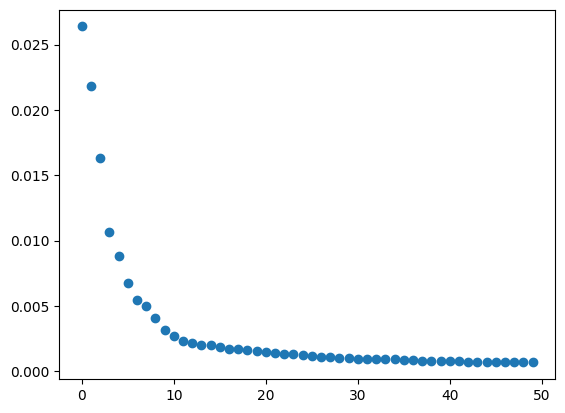

In [120]:
plt.scatter(range(50), adata.uns['pca']['variance_ratio'])

In [121]:
sc.pp.pca(adata, n_comps=kneedle.knee)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

computing PCA
    on highly variable genes
    with n_comps=10
    finished (0:00:15)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PC1', 'PC2', ..., the loadings (adata.var)
    'pca_variance', the variance / eigenvalues (adata.uns)
    'pca_variance_ratio', the variance ratio (adata.uns)
computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 10


/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    computed neighbors (0:00:21)
    computed connectivities (0:00:08)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:30)
computing UMAP


  2% 3/200 [00:00<00:58,  3.39it/s]

	completed  0  /  200 epochs


 11% 22/200 [00:07<00:58,  3.05it/s]

... (15 outputs left out)

 91% 182/200 [00:58<00:05,  3.08it/s]

	completed  180  /  200 epochs


100% 200/200 [01:04<00:00,  3.09it/s]

    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:01:14)


In [122]:
adata.obs['haveVariant'] = pd.Categorical(adata.obs['variant'] != 'None')
adata.obs['haveVariant'].value_counts()

haveVariant
True     95892
False    28094
Name: count, dtype: int64

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/usr/local/lib/python3.10/dist-packages/scanpy/plotting

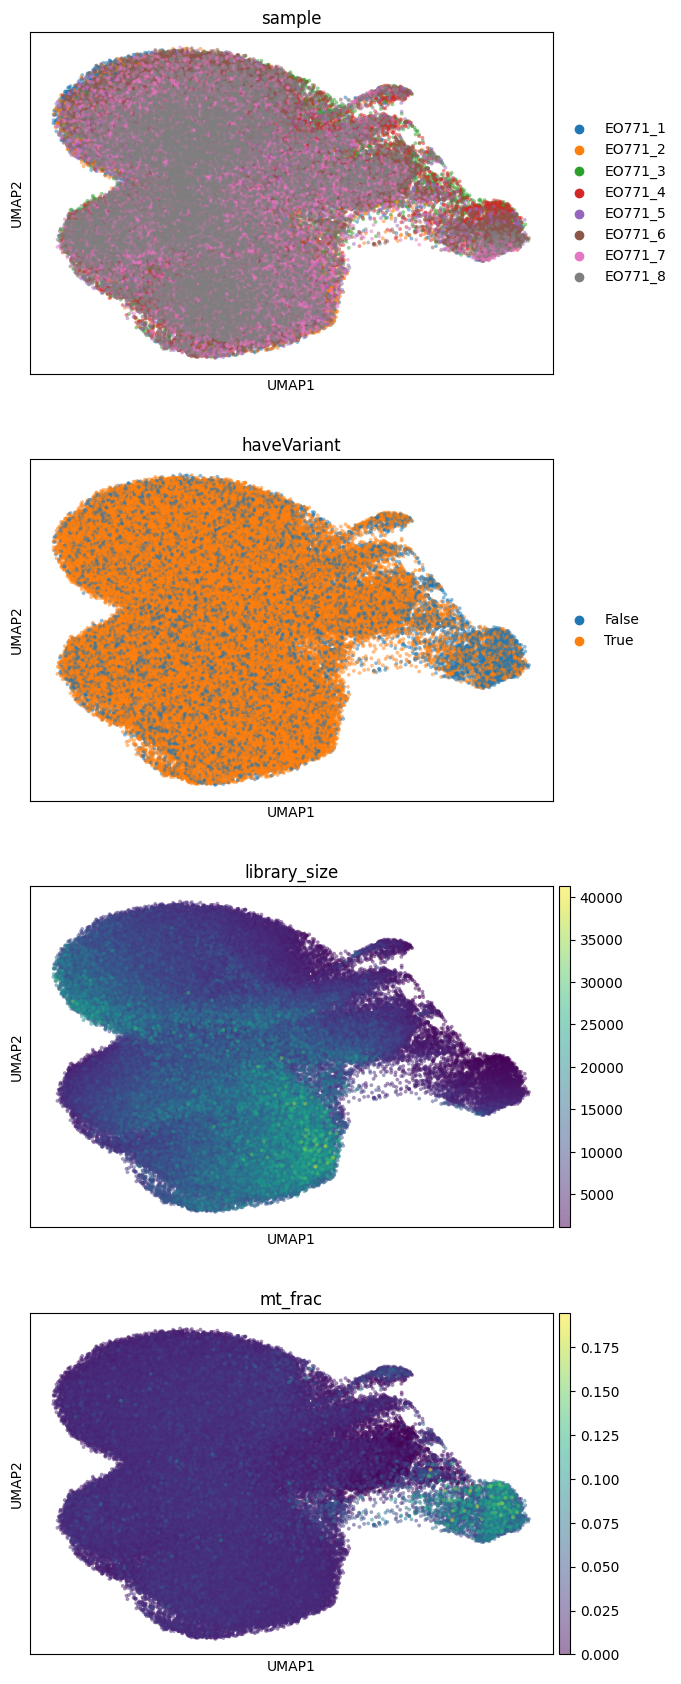

In [123]:
sc.pl.umap(adata, color=['sample', 'haveVariant', 'library_size', 'mt_frac'], ncols=1, s=30, alpha=0.5)

In [124]:
adata.obs['variant'].value_counts().iloc[:20]

variant
None         28094
mSTING_WT     4266
STOP          2797
V143X          998
L26X           809
A48X           743
Y3X            701
L30X           692
A232X          678
A84X           648
S29X           645
M31X           629
F25X           623
A67X           620
L47X           614
L258X          605
T139X          594
H185X          591
V27X           584
I93X           581
Name: count, dtype: int64

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/usr/local/lib/python3.10/dist-packages/scanpy/plotting

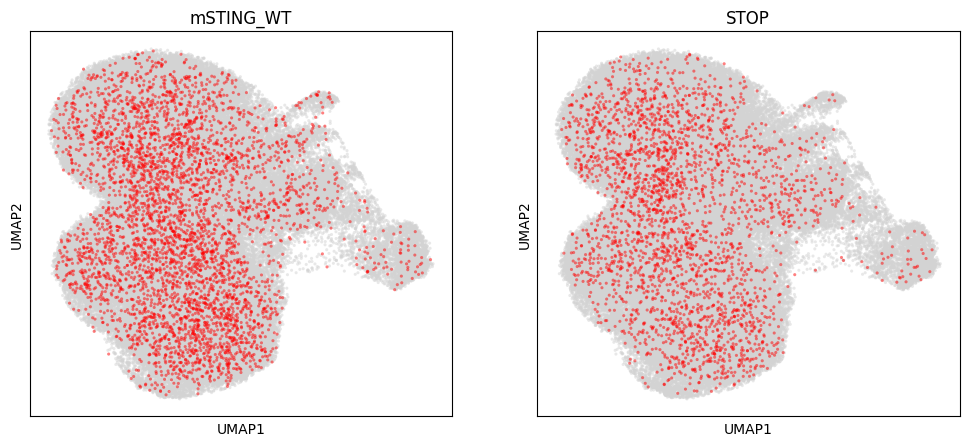

In [125]:
plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
for i, variant in enumerate(['mSTING_WT', 'STOP']):
    f = adata.obs['variant'] == variant
    ax = plt.subplot(1, 2, i+1)
    adata.obs['tmp'] = pd.Categorical(f, categories=[True, False])
    adata.uns['tmp_colors'] = ['red', 'lightgray']
    sc.pl.umap(adata[~f], color='tmp', ax=ax, title=variant, legend_loc=None, show=False, s=20, alpha=0.5)
    f = adata.obs['tmp'] == True
    sc.pl.umap(adata[f], color='tmp', ax=ax, title=variant, legend_loc=None, show=False, s=20, alpha=0.5)
plt.show()

In [126]:
## save to file
adata.write(f'{output_dir}/adata_{run_name}.h5ad')